# Машинное обучение, ФКН ВШЭ

## Практическое домашнее задание 2. Градиентный спуск своими руками



### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). **Максимально допустимая оценка за работу — 10 баллов + 0.5 за социальный бонус.**

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Напомним, что использовать генеративные модели (ChatGPT, GitHub Copilot и прочие) можно при вознекновении затруднений с выполнением отдельных частей домашей работы. Но если вы их применяете, то обязательно нужно сделать следующее:

1. Указывать, какие части ДЗ выполнены с использованием генеративных моделей.

2. Добавить в конец вашего решения небольшой раздел с рефлексией, где вы описываете, как подбирали промпты, какие заметили преимущества и недостатки генеративных моделей при выполнении данного ДЗ.

Но: Даже при использовании генеративных моделей студент должен полностью разбираться в сдаваемых задачах.

Также преподаватели и ассистенты могут вызвать студента на защиту домашней работы. Если на защите студент не сможет дать пояснения по своим решениям, это будет расцениваться как дисциплинарное нарушение и оценка за домашнее задание будет равна 0. После защиты преподаватели и ассистенты оставляют за собой право изменить оценку в любую сторону.

При наличии уважительной причины, дедлайн по домашнему заданию переносится на количество дней, равное продолжительности уважительной причины.

### Формат сдачи

Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием, а также файлы `descents.py`, `linear_regression.py` и `interfaces.py`. Сам ноутбук называйте в формате **homework-practice-02-gd-Username.ipynb**, где Username - ваша фамилия.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка**: 9


### О задании

В данном задании необходимо реализовать обучение линейной регрессии с помощью различных модификаций градиентного спуска. В файле `descents.py` вам нужно будет реализовать несколько классов для различных вариаций градиентного спуска, а именно:
* `VanillaGradientDescent`
* `StochasticGradientDescent`
* `SAGDescent`
* `MomentumDescent`
* `Adam`


В файле `linear_regression.py` вам необходимо будет реализовать класс `CustomLinearRegression` для обучения линейной регрессии (и, разумеется, предсказания целевой переменной на основе обученной модели).


### Про предложенную архитектуру

Предложенная вам архитектура шаблонов написана по принципам SOLID: основная ее идея в том, что вы сможете использовать различные лоссы и оптимизаторы с одним и тем же кодом прочих классов, никак не изменяя и не переписывая методы классов, которые с оптимизаторами и лоссом взаимодействуют. Мы добиваемся этого при помощи выделения интерфейсов (в Python мы достигаем этого при помощи абстрактных классов, см дальше в заданиях) и выделения зон ответственности каждого класса.

Глобально в нашей архитектуре всего 4 интерфейса (некоторые из которых на самом деле сразу concrete классы), каждый из которых порождает одно семейство:
- `interfaces.LossFunction`
  - Классы, имплементирующие этот интерфейс, отвечают за одну конкретную функцию потерь, используемую при обучении, и всё, что меняется вместе с ней при её замене: подсчёт лосса, подсчет градиента и аналитическое решение (если есть, то добавляется в интерфейс соответствующим mixin-ом).
- `interfaces.LinearRegressionInterface`
  - Интерфейс обертки для модели линейной регрессии, контейнер, содержащий составные части (лосс-функцию и оптимизатор) и использующий их для выполнения содержательной работы.
- `interfaces.LearningRateSchedule`
 - Простенькое семейство расписаний, определяющих шаг обучения для каждой итерации
- `interfaces.AbstractOptimizer`.
  -  Классы, имплементирующие этот интерфейс, имплементируют конкретный алгоритм оптимизации и всё, что происходит в его процессе. Пользуются обёрткой линейной регрессии для доступа к данным и вызова расчетов, чтобы не зависеть напрямую от конкретных функций потерь и шедулеров шага обучения.

Концепция передачи маленьких объектов, отвечающих за свою маленькую зону ответственности внутрь более сложного объекта для выполнения ими составных частей работы называется Dependency Injection, и работает как раз за счет выделения зоны ответственности и опоры на интерфейс вместо реализации.

Посмотрите на код `linear_regression.CustomLinearRegression`: она принимает в себя объекты с интерфейсами `LossFunction` и `AbstractOptimizer`, а в `descents.BaseDescent` как уточнении интерфейса абстрактного оптимизатора до итеративных оптимизаторов видно, что он в свою очередь принимает при инициализации объект шедулера шага обучения.

Благодаря этому, код, который использует эти классы, может по очереди:
- Инициализировать нужный шедулер с нужными параметрами для задания шага обучения
- Иницализировать оптимизатор, задав ему нужные параметры процесса и передав готовый шедулер
- Инициализировать класс линейной регрессии нужной под задачу функцией потерь и уже готовым оптимизатором.
- Запустить процесс обучения

И на любом этапе можно использовать другой объект с подходящим интерфейсом, и всё будет работать!


**В ходе выполнения этой домашки вы наполните все эти семейства классов различными имплементациями и будете менять их на ходу как перчатки!**

Более подробно про наследование классов в Python можно прочитать здесь:
* Наследование: https://docs.python.org/3/tutorial/classes.html#inheritance
* Абстрактные классы: https://docs.python.org/3/library/abc.html



## Задание 1. Линейная регрессия  (1 балл)

### Градиент функции потерь MSE

На семинаре про [матрично-векторное дифференцирование](https://github.com/esokolov/ml-course-hse/blob/master/2025-fall/seminars/sem03-vector-diff.pdf) вы должны были обсуждать дифференцирование функции потерь MSE в матричном виде.

### Задание 1.0. Градиент MSE в матричном виде (0.3 балла).

Напомним, что функция потерь MSE записывается как:

$$
    Q(w) = \frac{1}{\ell} \sum \limits_{i = 1}^\ell (y_i - \langle x_i, w \rangle)^2 = \frac{1}{\ell} \| X w - y \|^2
$$

где $\ell$ – количество объектов в выборке, $X \in \mathbb{R}^{\ell \times d}$ – матрица "объект-признак", а $y \in \mathbb{R}^\ell$ – целевая переменная. Через $x_i$ обозначается $i$-ая строчка матрицы $X$, отвечающая за $i$-й объект выборки.

- **Выпишите ниже (подсмотрев в семинар или решив самостоятельно) градиент для функции потерь MSE в матричном виде.**

**Решение:**

$$
d Q(W) = d(\frac{1}{\ell} \| X w - y \|^2) = \frac{1}{\ell} d(\| X w - y \|^2) = \frac{1}{\ell} d \langle X w - y, Xw - y \rangle = \frac{2}{\ell} \langle X w - y, d(Xw - y) \rangle
$$
$$
d Q(W) = \frac{2}{\ell} \langle X w - y, Xdw \rangle = \frac{2}{\ell} \langle X^T (X w - y), dw \rangle 
$$

$$
   \nabla Q(w) = \frac{2}{\ell} X^T (X w - y)
$$


- **Имплементируйте методы `MSELoss.loss`, `MSELoss.gradient`**





### Задание 1.1 Аналитическое решение и `CustomLinearRegression` (0.7 балла)

Перед тем, как мы углубимся в итеративные методы оптимизации, давайте вспомним, что для ряда функций потерь существует и аналитическое решение. Давайте сперва вспомним, как оно выглядит для MSE.

- **Выведите формулу оптимальных $w$ в задаче минимизации MSE, и запишите её ниже.**

- **Имплементируйте подсчет этого решения в `MSELoss._plain_analytic_solution`**

$$\text{MSE} = \| X w - y \|^2$$
$$
   w = (X^T X)^{-1} X^T y
$$

Необходимое условие - градиент в точке минимума должен равняться нулю:

$$
   \nabla Q(w) = \frac{2}{\ell} X^T (X w - y) = 0
$$

$$
   X^T (X w - y) = 0
$$

$$
   X^T X w  = X^T y
$$

$$
   w = (X^T X)^{-1} X^T y
$$

Функция выпуклая, поэтому раз мы нашли единственную точку, где градиент равен нулю, то она и является минимумом.

**Вопрос**: Как мы помним, у аналитического решения есть минусы - какие?

**Ответ**:

1) Долго считать - асимптотика $O(d^3 + d^2l)$

2) Решение вычислительно нестабильно (особенно если матрица плохо обусловлена). А $X^TX$ может быть вообще необратима.

Теперь прокинем это решение в наш класс линейной регрессии, чтобы получше разобраться в архитектуре.


- **Допишите класс `descents.AnalyticSolutionOptimizer`**
- **Допишите класс `CustomLinearRegression`**
  - В нем на текущем этапе нужно имплементировать все методы: `fit` и `predict` вам понадобятся прямо сейчас, а `compute_gradients` и `compute_loss` в следующей части.

Помните, про разделение ответственности классов!

За контроль процесса обучения отвечает оптимизатор, а объект линейной регрессии по факту выступает точкой входа, контейнером для данных и способом доступа к вычислениям, на основе которых оптимизатор принимает решения (e.g. значение антиградиента в точке весов).

При этом сам по себе оптимизатор должен быть универсален, в нем никак не должны содержаться детали, связанные с конкретными функциями потерь, все необходимое от них он может получить через `self.model`.

Аналогично, класс линейной регрессии тоже должен быть универсальным и готовым к работе с любыми лоссами и оптимизаторами, исполняющими заявленный интерфейс. Здесь применена dependency injection, и вы должны грммотно ее поддержать в своей имплементации. Аналогично, все, что вам может быть нужно от функций потерь, вы можете получить при помощи обращения к переданному объекту.

In [1]:
import numpy as np
from linear_regression import MSELoss, CustomLinearRegression, AnalyticSolutionOptimizer

num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

In [2]:
from sklearn.metrics import mean_squared_error as mse
from sklearn.linear_model import LinearRegression # у меня иначе был AttributeError: module 'sklearn' has no attribute 'linear_model'
import sklearn

sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.08616982372033506
Your MSE 0.08616982372033508


Давайте сделаем задание немного прикольнее и изменим одну из колонок. Как мы знаем, полная мультиколлинеарность запрещает нам пользоваться аналитическим решением, но `sklearn` по какой-то причине это обходит, хмм

In [3]:
x[:, 3] = x[:, 2] + x[:, 4]

In [4]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

Sklearn MSE 0.08777775103269717
Your MSE 1.046128209122374


Ваша задача - понять, как можно сделать так, чтобы аналитическое решение работало всегда, вне зависимости от матрицы X. Как оказывается, это можно сделать, если воспользоваться SVD разложением. Для имплементации воспользуйтесь `scipy.sparse.linalg.svds`.

- Выведите через SVD формулу оптимальных $w$ в задаче минимизации MSE.

- Имплементируйте подсчет этого решения в `MSELoss._svd_analytic_solution`
    - Мир итерационных агоритмов причудлив. Если вы посмотрите на опции солверов svds, то увидите, что возможности вычислить точно все сингулярные числа вам не дают (propack рандомизированный и даст вам неточные ответы). Используйте стандартный солвер, выставьте максимальную доступную точность.

- Ответьте на **вопрос на засыпку**. Вообще говоря, в ряде случаев (например в нашем), даже такая неабсолютная на первый взгляд точность все равно позволяет получить точное решение задачи. Обоснуйте, почему? Как называется такой вид SVD? Какого минимального числа сингулярных чисел с вероятностью 1 будет достаточно в нашем случае для получения точного решения? Обоснуйте, почему.


**Ответ**:
$$\text{X} = \underset{n\times m}{\mathrm{U}} \ \underset{m\times m}{\mathrm{\Sigma}} \ \underset{m\times k}{\mathrm{V^T}}$$

$$ \| X w - y \|^2 \rightarrow min $$

$$ \| U \Sigma V^T w - y \|^2 \rightarrow min $$

Домножим слева на $U^T$ (она ортогональна, поэтому норма не изменится)

$$ \| \Sigma V^T w - U^T y \|^2 \rightarrow min $$

Обозначим $a = V^T w, b = U^T y, r = rk(\Sigma) $

$$ \| \Sigma a - b \|^2 \rightarrow min $$

$$ \sum_{i = 1}^r (\sigma_i a_i - b_i) ^ 2 +  \sum_{r + 1}^\ell y_i^2 \rightarrow min $$

$$ \sum_{i = 1}^r (\sigma_i a_i - b_i) ^ 2 \rightarrow min$$

$$ a_i = \frac{b_i}{\sigma_i}, i \leq r $$

$$ a_i = 0, i > r $$

Обозначим $S$ матрицу, на диагонали которой первые $r$ элементов - обратные к $\sigma_i$, а остальные нули.

Тогда $a = Sb$

$$ V^Tw = SU^Ty $$

$$ w = V S U^T y$$

In [5]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))


your_linreg =  CustomLinearRegression(AnalyticSolutionOptimizer(),
                                      loss_function=MSELoss(analytic_solution_func=MSELoss._svd_analytic_solution))
your_linreg.fit(x, y)

print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.08777775103269717
Your MSE 0.08777775103269717


## Задание 2. Реализация градиентного спуска (4 балла)

В этом задании вам предстоит написать собственные реализации различных подходов к градиентному спуску с опорой на подготовленные шаблоны в файле `descents.py`. При помощи них мы будем искать итеративные решения, подавая оптимизаторы внутрь нашей `CustomLinearRegression`.

### Напоминание про градиентный спуск

Основное свойство антиградиента &ndash; он указывает в сторону *наискорейшего* убывания функции в данной точке. Соответственно, будет логично стартовать из некоторой точки, сдвинуться в сторону антиградиента,
пересчитать антиградиент и снова сдвинуться в его сторону и т.д. Запишем это более формально.

Пусть $w_0$ &ndash; начальный набор параметров (например, нулевой или сгенерированный из некоторого
случайного распределения). Тогда ванильный градиентный спуск состоит в повторении следующих шагов до сходимости:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

Здесь $\eta_{k}$ обозначает длину шага на $k$-ой итерации (learning rate), а $Q(w)$ - функцию потерь (loss function).

Градиент для MSE вы уже нашли выше

### Задание 2.0. Learning Rate Schedules (0.2 балла)

Обратите внимание на **абстрактный** класс `LearningRateSchedule` в файле `descents.py`. С помощью его имплементаций мы на каждой итерации градиентного спуска будем получать соответствующий `learning_rate` $\eta_k$.

В файле уже реализован класс `ConstantLR`, который на каждой итерации возвращает один и тот же заранее заданный шаг. **Ваша задача в этом пункте – реализовать `TimeDecayLR`**, который мы будем использовать для обучения линейной регрессии. Формула очередного шага должна выглядеть следующим образом:
$$
    \eta_{k} = \lambda \left(\dfrac{s_0}{s_0 + k}\right)^p
$$

На практике достаточно настроить параметр $\lambda$, а остальным выставить параметры по умолчанию: $s_0 = 1, \, p = 0.5.$

### Задание 2.1. Родительский класс BaseDescent (1 балл).


Внимательно изучите устройство класса `BaseDescent`. У него есть один непомеченный абстрактным метод, который ему как частичному наследнику абстрактного класса нужно имплементировать - это `optimize`. В
этом методе необходимо имплементировать основной цикл обучения, и далее его будут переиспользовать все его наследники.

- **Допишите метод `BaseDescent.optimize`**


Для этого и всех дальнейших заданий необходимо соблюдать следующие условия:

* **Все вычисления должны быть векторизованы;**
* Циклы средствами python допускаются только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):
    * Квадрат евклидовой нормы разности весов на двух соседних итерациях меньше `tolerance`;
    * Разность весов содержит наны;
    * Достижение максимального числа итераций `max_iter`.
* Будем считать, что все данные, которые поступают на вход имеют столбец единичек последним столбцом;
* Веса модели надо обновлять внутри функции `_update_weights`, она неспроста так называется
* Чтобы проследить за сходимостью оптимизационного процесса будем использовать `CustomLinearRegression.loss_history`, в нём будем хранить *значения функции потерь до каждого шага, начиная с нулевого* (до первого шага по антиградиенту) и *значение функции потерь после оптимизации*.


Обратите внимание, что метод `_update_weights` всё ещё является абстрактным - его все ещё должны будут имплементировать дальнейшие наследники; фактически, только способом обновления весов они и отличаются. Она должна должна обновлять веса модели `self.model.w`, а также возвращать величину обновления $w_{k + 1} - w_k$.

Также обратите внимание на атрибут `self.iteration`, отвечающий за номер итерации алгоритма спуска. Как раз с помощью него (и `self.lr_schedule`) мы и будем получать `learning_rate` на соответствующей итерации алгоритма.

**Обратите внимание**

*да, в третий раз*

Все реализуемые вами классы спуска в задании - это *универсальные* оптимизаторы. Они не должны считать градиенты конкретной функции потерь внутри себя.

Для вычисления градиента они всегда обращаются к модели, с которой работают:

```
gradient = self.model.compute_gradients(X_batch, y_batch)
```

### Задание 2.2. Полный градиентный спуск VanillaGradientDescent (0.6 балла).

Реализуйте полный градиентный спуск заполнив пропуски в классе `VanillaGradientDescent` в файле `descents.py`. Напомним, что шаг классического градиентного спуска выглядит следующим образом:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

**Важно**: Здесь и далее функция `_update_weights` должна возвращать разницу между $w_{k + 1}$ и $w_{k}$: $\quad w_{k + 1} - w_{k} = -\eta_{k} \nabla_{w} Q(w_{k})$. Кроме того, соответственно своему названию, она должна обновлять веса модели `model.w`.

### Напоминание про SGD (стохастических градиентный спуск)

Как правило, в задачах машинного обучения функционал $Q(w)$ представим в виде суммы $\ell$ функций:

$$
    Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        q_i(w).
$$

В нашем домашнем задании отдельные функции $q_i(w)$ соответствуют ошибкам на отдельных объектах.

Проблема метода градиентного спуска состоит в том, что на каждом шаге необходимо вычислять градиент всей суммы (будем его называть полным градиентом):

$$
    \nabla_w Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        \nabla_w q_i(w).
$$

Это может быть очень трудоёмко при больших размерах выборки. В то же время точное вычисление градиента может быть не так уж необходимо &ndash; как правило, мы делаем не очень большие шаги в сторону антиградиента, и наличие в нём неточностей не должно сильно сказаться на общей траектории.

Оценить градиент суммы функций можно средним градиентов случайно взятого подмножества функций:

$$
    \nabla_{w} Q(w_{k}) \approx \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}),
$$
где $B$ - это случайно выбранное подмножество индексов, обычно называемое **батчом**.

Оценка $\frac{1}{|B|} \sum \limits_{i \in B} \nabla_w q_i(w_k)$ называется **стохастическим градиентом** функции потерь, а получившийся метод называют методом **стохастического градиентного спуска** или просто SGD.

### Задание 2.3. Стохастический градиентный спуск StochasticGradientDescent (0.7 балла).

Реализуйте стохастический градиентный спуск, заполнив пропуски в классе `StochasticGradientDescent`. Для оценки градиента используйте формулу выше (среднее градиентов случайно выбранного батча объектов). Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}).
$$

Размер батча будет являться **гиперпараметром** метода и передаваться в конструктор класса `__init__(...)`. Семплировать индексы батча объектов $B$ можно с повторениями (через np.random.randint) - это допустимо и даёт несмещённую оценку градиента. По желанию можно без повторений (np.random.choice(..., replace=False) или через пермутацию по эпохам).

### Задание 2.4 Stochastic Average Gradient (0.6 балла)

Держим память последних индивидуальных градиентов $g_i$ по всем объектам и их среднее $\bar g = \frac{1}{\ell}\sum_i g_i$. На каждом шаге выбираем индексы $j$ (мини-батч), заново считаем $g_j^{new}(w_k)$, обновляем среднее:
$$
\bar g \leftarrow \bar g + \frac{1}{\ell}\bigl(g_j^{new} - g_j^{old}\bigr),\qquad
w_{k+1} = w_k - \eta_k \bar g.
$$
Инициализация: $g_i=0 \Rightarrow \bar g=0$.

Так получаем шаг почти как у полного градиента, но считаем градиент лишь на нескольких объектах за итерацию.

Реализуйте класс `SAGDescent` в `descents.py` с хранением `grad_memory` и `avg_grad`. Подсказка: чтобы получить пер-объектный градиент, можно вызывать `compute_gradients` на срезе из одного объекта `X[j:j+1]` или на фильтрованной индексами матрице для батча.

**Имейте в виду, что SAG достаточно капризный**: для его сходимости (и ее скорости) достаточно важен размер батча. Для вас установлено дефолтное значение, но на реальных данных его может быть недостаточно. В сравнениях методов ниже вам может понадобится подобрать значение размера батча, чтобы раскрыть потенциал метода. То ж касается и SGD, но в меньшей степени.

### Напоминание про метод инерции (или метод моментов)

Может оказаться, что направление антиградиента сильно меняется от шага к шагу. Например, если линии уровня функционала сильно вытянуты, то из-за ортогональности градиента линиям уровня он будет менять направление на почти противоположное на каждом шаге. Такие осцилляции будут вносить сильный шум в движение, и процесс оптимизации займёт много итераций. Чтобы избежать этого, можно усреднять векторы антиградиента с нескольких предыдущих шагов &ndash; в этом случае шум уменьшится, и такой средний вектор будет указывать в сторону общего направления движения. Введём для этого вектор инерции:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k})
\end{align}

Здесь $\alpha$ &ndash; параметр метода, определяющей скорость затухания градиентов с предыдущих шагов. Разумеется, вместо вектора градиента может быть использована его аппроксимация (например, в случае **стохастического градиентного спуска**). Чтобы сделать шаг градиентного спуска, просто сдвинем предыдущую точку на вектор инерции:

$$
    w_{k + 1} = w_{k} - h_{k + 1}.
$$

Заметим, что если по какой-то координате градиент постоянно меняет знак, то в результате усреднения градиентов в векторе инерции эта координата окажется близкой к нулю. Если же по координате знак градиента всегда одинаковый, то величина соответствующей координаты в векторе инерции будет большой, и мы будем делать большие шаги в соответствующем направлении.

### Задание 2.5 Метод Momentum - MomentumDescent (0.5 балла).

Реализуйте градиентный спуск с методом инерции заполнив пропуски в классе `MomentumDescent`. Шаг оптимизации:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k}) \\
    &w_{k + 1} = w_{k} - h_{k + 1}.
\end{align}

$\alpha$ являеться гиперпараметром метода, однако в данном домашнем задании мы зафиксируем её за вас $\alpha = 0.9$.

### Напоминание про AdaGrad, RMSprop и Adam

Градиентный спуск очень чувствителен к выбору длины шага. Если шаг большой, то есть риск, что мы будем перескакивать через точку минимума; если же шаг маленький, то для нахождения минимума потребуется много итераций. При этом нет способов заранее определить правильный размер шага &ndash; к тому же, схемы с постепенным уменьшением шага по мере итераций могут тоже плохо работать.

В методе AdaGrad предлагается сделать свою длину шага для каждой компоненты вектора параметров. Идея проста: мы будем "копить" сумму квадратов градиентов и делить очередной градиент на корень из этой суммы. Таким образом, обновление весов с большими градиентами будет тормозиться, а с маленькими наоборот получать большие шаги. Формула обновлени будет выглядить так:

\begin{align}
    &G_{kj} = G_{k-1,j} + (\nabla_w Q(w_{k - 1}))_j^2; \\
    &w_{jk} = w_{j,k-1} - \frac{\eta_t}{\sqrt{G_{kj}} + \varepsilon} (\nabla_w Q(w_{k - 1}))_j.
\end{align}

Здесь $\varepsilon$ небольшая константа, которая предотвращает деление на ноль.

В данном методе можно зафиксировать длину шага (например, $\eta_k = 0.01$) и не подбирать её в процессе обучения **(обратите внимание, что в данном домашнем задании длина шага не фиксируется)**. Отметим, что данный метод подходит для разреженных задач, в которых у каждого объекта большинство признаков равны нулю. Для признаков, у которых ненулевые значения встречаются редко, будут делаться большие шаги; если же какой-то признак часто является ненулевым, то шаги по нему будут небольшими.

У метода AdaGrad есть большой недостаток: переменная $G_{kj}$ монотонно растёт, из-за чего шаги становятся всё медленнее и могут остановиться ещё до того, как достигнут минимум функционала. Проблема решается в методе RMSprop, где используется экспоненциальное затухание градиентов:

$$
    G_{kj} = \alpha G_{k-1,j} + (1 - \alpha) (\nabla_w Q(w^{(k-1)}))_j^2.
$$

В этом случае размер шага по координате зависит в основном от того, насколько
быстро мы двигались по ней на последних итерациях.

Можно объединить идеи описанных выше методов: накапливать градиенты со всех прошлых шагов для
избежания осцилляций (метод инерции), а также делать адаптивную длину шага по каждому параметру (`RMSProp`). Таким образом, мы получим метод `Adam` с той лишь разницей, что в методе `Adam` дополнительно делается нормировка накопленных градиентов и квадратов градиентов для устранения смещения.

### Задание 2.6. Метод Adam (Adaptive Moment Estimation) (0.4 балла).

Реализуйте градиентный спуск с методом Adam, заполнив пропуски в классе `Adam`. Шаг оптимизации:

\begin{align}
    &m_0 = 0, \quad v_0 = 0; \\ \\
    &m_{k + 1} = \beta_1 m_k + (1 - \beta_1) \nabla_w Q(w_{k}); \\ \\
    &v_{k + 1} = \beta_2 v_k + (1 - \beta_2) \left(\nabla_w Q(w_{k})\right)^2; \\ \\
    &\widehat{m}_{k} = \dfrac{m_k}{1 - \beta_1^{k}}, \quad \widehat{v}_{k} = \dfrac{v_k}{1 - \beta_2^{k}}; \\ \\
    &w_{k + 1} = w_{k} - \dfrac{\eta_k}{\sqrt{\widehat{v}_{k + 1}} + \varepsilon} \widehat{m}_{k + 1}.
\end{align}

$\beta_1 = 0.9, \beta_2 = 0.999$ и $\varepsilon = 10^{-8}$ будут зафиксированы за вас.

## Задание 3. Проверка кода (0 баллов)

Данная секция нужна для того, чтобы убедиться в правильности реализации методов спуска и класса `CustomLinearRegression`. В начале мы сделаем небольшую локальную проверку на "адекватность" и "запускаемость" ваших моделей, после чего уже можно будет делать посылки в Яндекс Контест.

In [6]:
%load_ext autoreload

In [7]:
%autoreload 2

from descents import (
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam
)

from linear_regression import CustomLinearRegression

In [8]:
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

Проверяем код на запускаемость.

In [9]:
descent_models = [
   VanillaGradientDescent,
   StochasticGradientDescent,
   SAGDescent,
   MomentumDescent,
   Adam
]

max_iter = 10
tolerance = 0
num_objects = 100
dimension = 5

for descent_model in descent_models:
   optimizer = descent_model(tolerance=tolerance, max_iter=max_iter)
   model = CustomLinearRegression(optimizer=optimizer)
   model.fit(x, y)
   assert len(model.loss_history) == max_iter + 1, "Loss history failed"
   y_pred = model.predict(x)
   assert y_pred.shape == y.shape, "Prediction shape does not match target variable"


Если ваше решение прошло все тесты локально, то теперь пришло время протестировать его в [Яндекс Контесте](https://new.contest.yandex.ru/contests/90083/start).

Для каждой задачи из контеста вставьте ID успешной посылки и ваш ник (почту):

* **Ник/почта**:
Егор Грачев
egpagrachev@edu.hse.ru

* **VanillaGradientDescent**:
169347532

* **StochasticGradientDescent**:
169348162

* **SAGDescent**:
169350000

* **MomentumDescent**:
169350493

* **Adam**:
169351362

* **LinearRegression**:
169368436

## Задание 4. Работа с данными (1 балл)

Мы будем использовать датасет объявлений по продаже машин на немецком Ebay. В задаче предсказания целевой переменной для нас будет являться цена.

* Постройте график распределения целевой переменной в данных, подумайте, нужно ли заменить её на логарифм. Присутствуют ли выбросы в данных с аномальной ценой? Если да, то удалите их из данных.

* Проведите исследование данных:
    * Проанализируйте тип столбцов, постройте графики зависимости целевой переменной от признака, распределения значений признака;
    * Подумайте (и напишите): какие признаки могут быть полезными на основе этих графиков, обработайте выбросы;
    * Подумайте (и напишите): какие трансформации признаков из известных вам будет уместно применить;
    * Разделите полезные признаки на категориальные, вещественные и те, которые не надо предобрабатывать.
* Разделите данные на обучающую, валидационную и тестовую выборки в отношении 8:1:1.

In [10]:
import numpy as np
import pandas as pd  # при желании, можете заменить на polars/pyspark или что угодно, что вам нравится

import matplotlib.pyplot as plt
import seaborn as sns

from descents import (
    ConstantLR, TimeDecayLR,
    VanillaGradientDescent, StochasticGradientDescent,
    MomentumDescent, Adam, SAGDescent
)
from linear_regression import CustomLinearRegression

%config InlineBackend.figure_format = 'retina'
plt.rcParams['figure.figsize'] = 8, 5
plt.rcParams['font.size'] = 12
plt.rcParams['savefig.format'] = 'pdf'
sns.set_style('darkgrid')

In [11]:
data = pd.read_csv('autos.csv')  # разумеется, если вы используете не pandas, это надо поменять

In [12]:
data.head()

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000


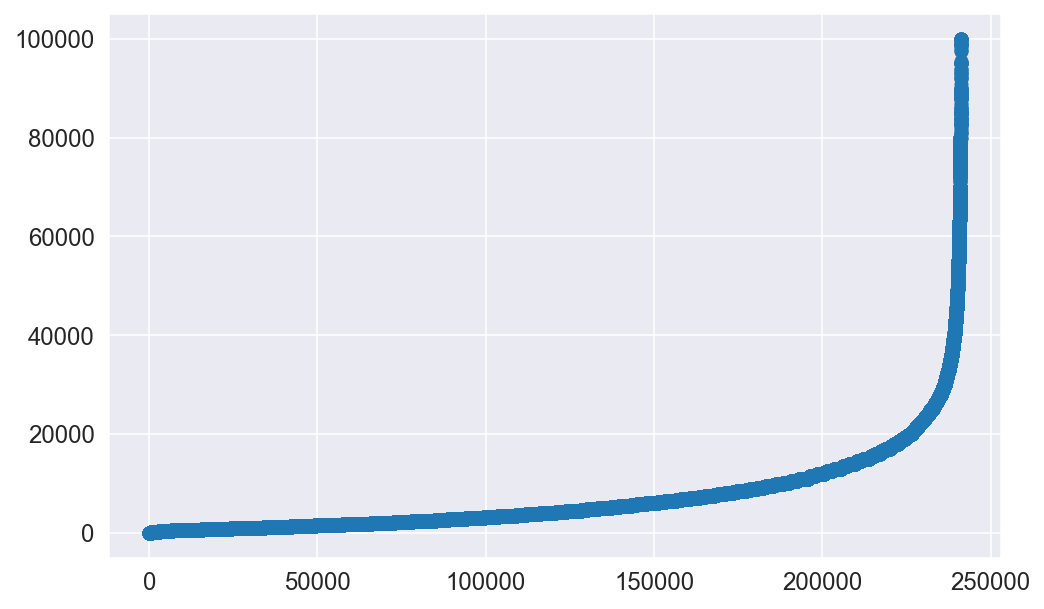

In [50]:
price = sorted(data["price"])

plt.scatter(range(len(price)), price)

<AxesSubplot:xlabel='price', ylabel='Count'>

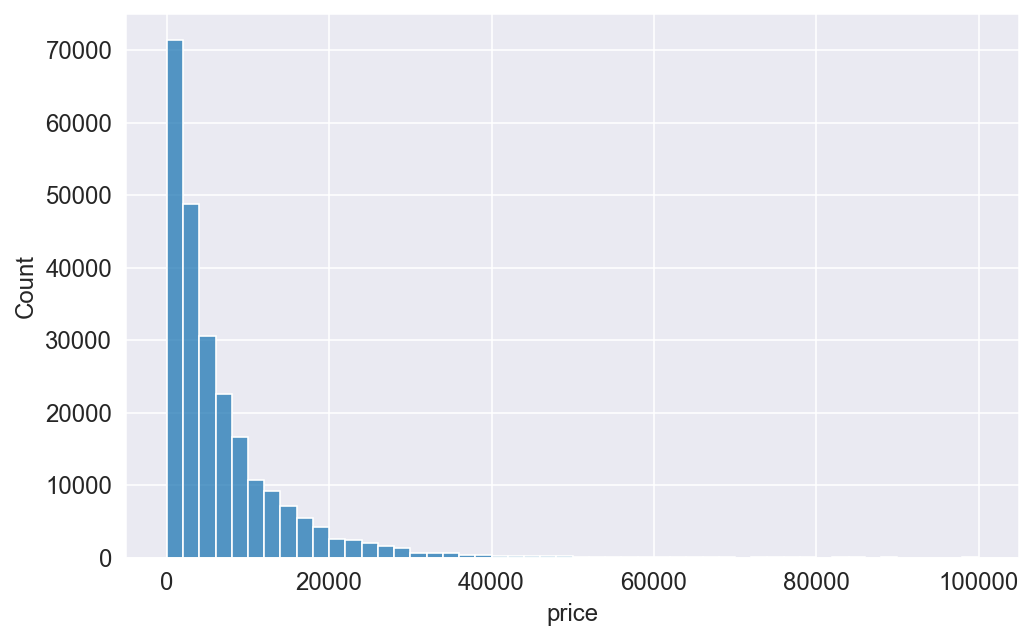

In [51]:
sns.histplot(data["price"], bins=50)

<AxesSubplot:xlabel='price', ylabel='Count'>

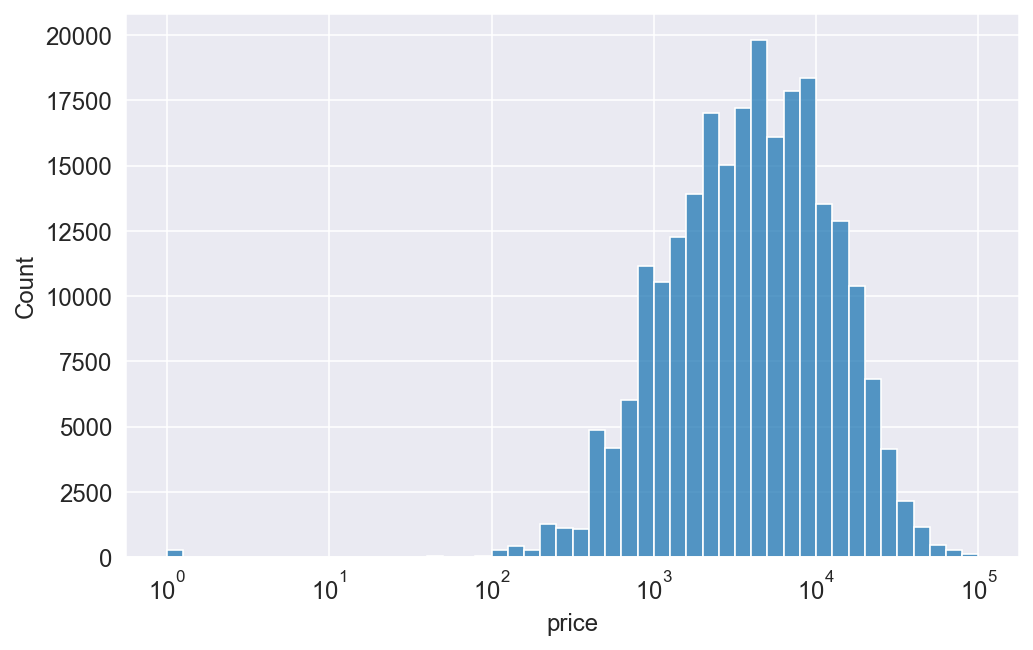

In [52]:
sns.histplot(data["price"], bins=50, log_scale=True)

По распределению мы видим, что значительно более осмысленно будет предсказывать логарифм цены: сама цена выглядит экспоненциально, а её логарифм похож на нормальное распределение.

In [13]:
data["price"].describe()

count    241190.000000
mean       6887.741892
std        8024.451993
min           1.000000
25%        1750.000000
50%        4100.000000
75%        8999.000000
max       99999.000000
Name: price, dtype: float64

In [14]:
print(len(data[data["price"] <= 1]))
print(len(data[data["price"] <= 2]))
print(len(data[data["price"] <= 3]))
print(len(data[data["price"] <= 10]))
print(len(data[data["price"] <= 50]))

274
278
280
292
361


Будем считать цену 1 выбросом, можно брать больше. Скорее всего, это те, кто хочет просто избавиться от машины и ставит символическую цену.

In [15]:
data[data["price"] >= 99999]

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
92147,nissan,x_trail,suv,manuell,diesel,nein,114,150000,175,99999
96067,porsche,911,cabrio,automatik,benzin,nein,400,20000,33,99999
204347,porsche,911,coupe,manuell,benzin,ja,325,150000,142,99999
222159,smart,fortwo,kleinwagen,automatik,benzin,nein,71,50000,78,99999


Ну допустим про порш я могу поверить, но вот nissan x_trail и smart fortwo	точно столько не стоят.

In [16]:
data[data["price"] >= 99000]

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
40327,porsche,911,cabrio,manuell,benzin,nein,165,5000,519,99500
44171,mercedes_benz,andere,cabrio,automatik,benzin,nein,150,30000,597,99000
72533,porsche,911,andere,manuell,benzin,nein,585,50000,143,99990
73774,porsche,911,coupe,manuell,benzin,nein,286,60000,225,99000
83440,porsche,911,coupe,manuell,benzin,nein,300,125000,340,99911
85946,land_rover,andere,suv,automatik,diesel,nein,220,150000,142,99000
92147,nissan,x_trail,suv,manuell,diesel,nein,114,150000,175,99999
95933,mercedes_benz,g_klasse,suv,automatik,diesel,nein,211,30000,58,99000
96067,porsche,911,cabrio,automatik,benzin,nein,400,20000,33,99999
118991,audi,andere,cabrio,automatik,benzin,nein,525,30000,34,99900


In [17]:
data.drop(data[data["price"] <= 1].index, inplace=True)
data.drop(data[data["price"] >= 99999].index, inplace=True)

In [18]:
data["price"].describe()

count    240912.000000
mean       6894.028512
std        8016.745313
min           2.000000
25%        1780.000000
50%        4127.500000
75%        8999.000000
max       99990.000000
Name: price, dtype: float64

In [19]:
data["price"] = np.log(data["price"])
data["price"].describe()

count    240912.000000
mean          8.273985
std           1.125523
min           0.693147
25%           7.484369
50%           8.325427
75%           9.104869
max          11.512825
Name: price, dtype: float64

Колонки в данных:

* `brand` - название бренда автомобиля
* `model` - название модели автомобиля
* `vehicleType` - тип транспортного средства
* `gearbox` - тип трансмисcии
* `fuelType` - какой вид топлива использует автомобиль
* `notRepairedDamage` - есть ли в автомобиле неисправность, которая еще не устранена
* `powerPS` - мощность автомобиля в PS (метрическая лошадиная сила)
* `kilometer` - сколько километров проехал автомобиль, пробег
* `autoAgeMonths` - возраст автомобиля в месяцах


* `price` - цена, указанная в объявлении о продаже автомобиля (целевая переменная)

Разделите признаки на категориальные, числовые и ... все остальное

In [20]:
categorical = ["brand", "model", "vehicleType", "gearbox", "fuelType", "notRepairedDamage"]
numeric = ["powerPS", "kilometer", "autoAgeMonths"]
other = []

C:\Users\grach\AppData\Local\Temp\ipykernel_15996\637868295.py:5: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=data, x="price", hue=col, common_norm=False, fill=True, legend=False)


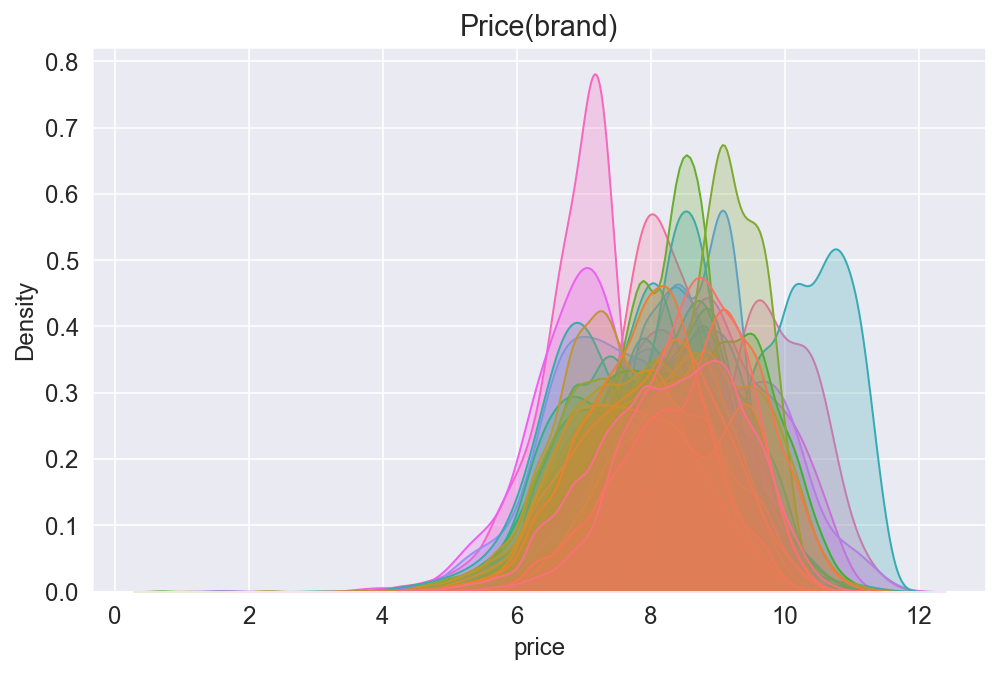

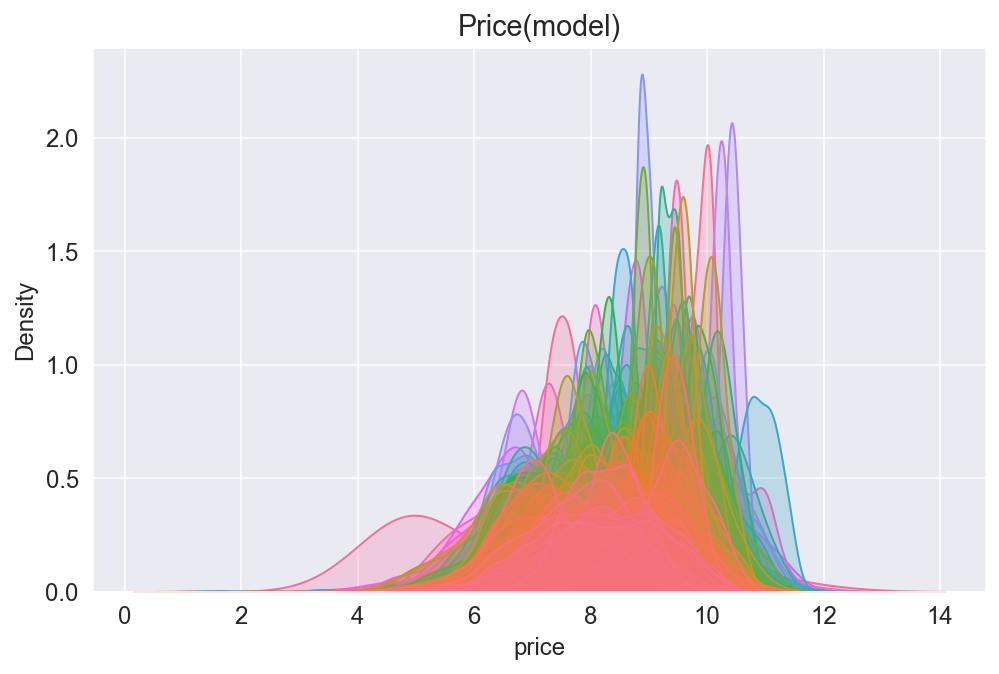

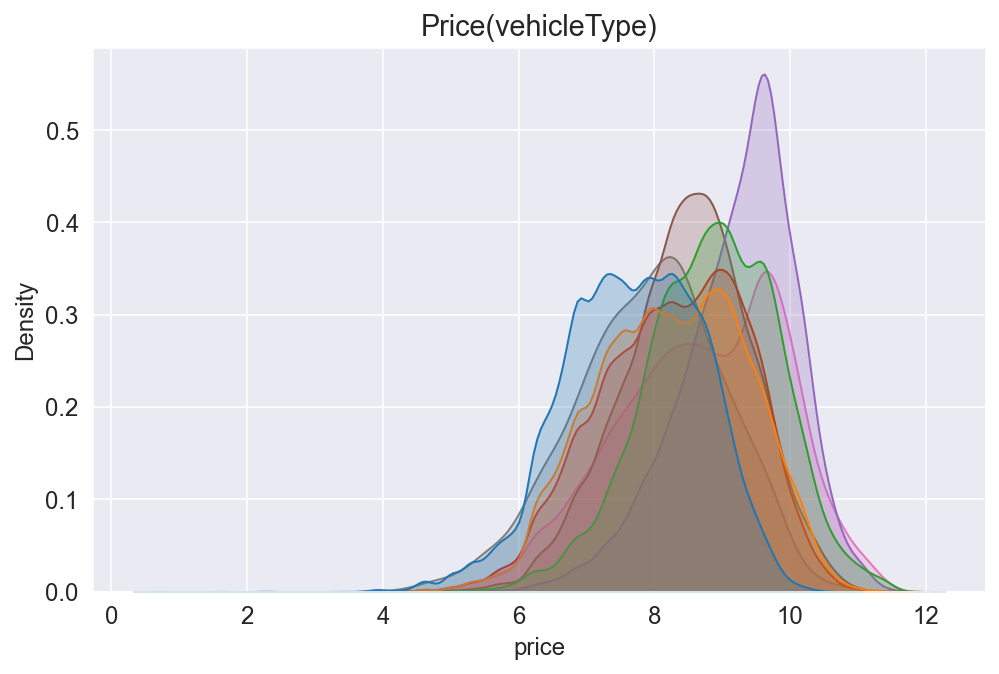

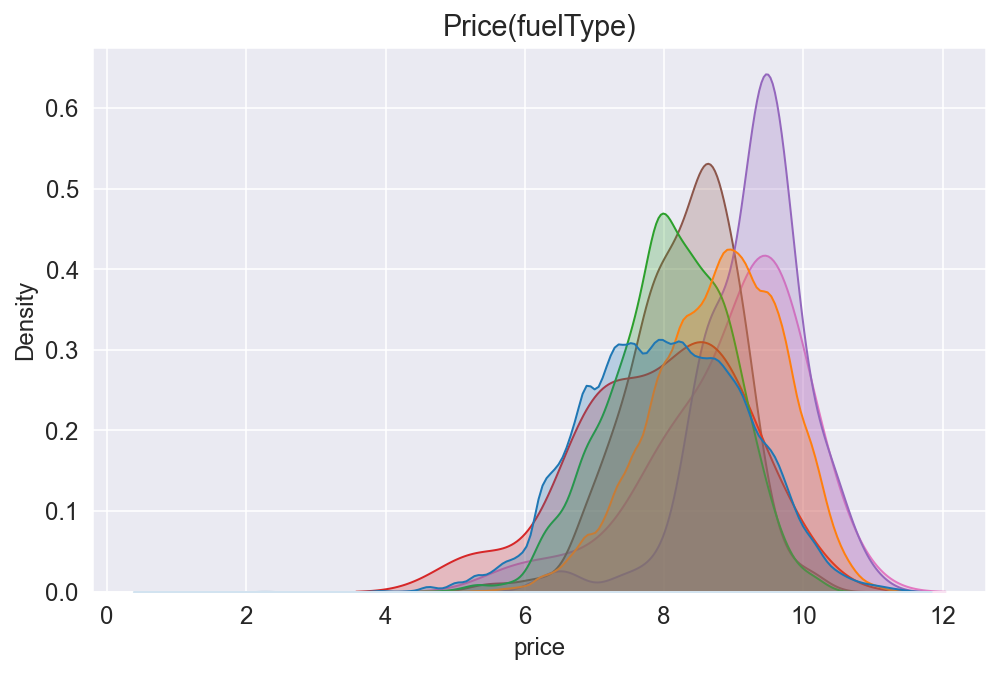

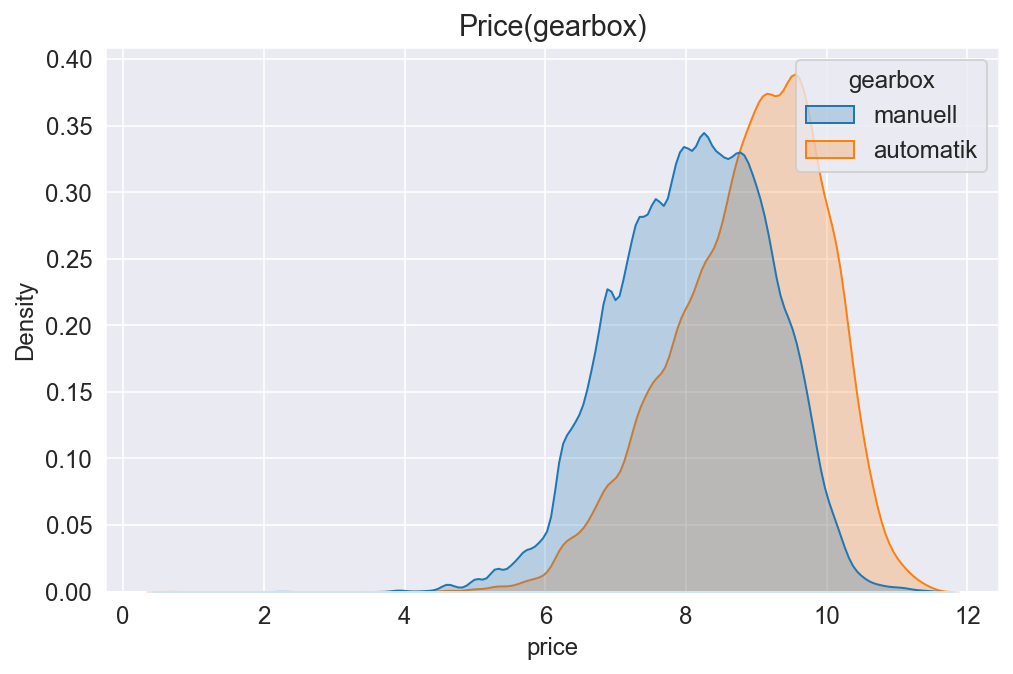

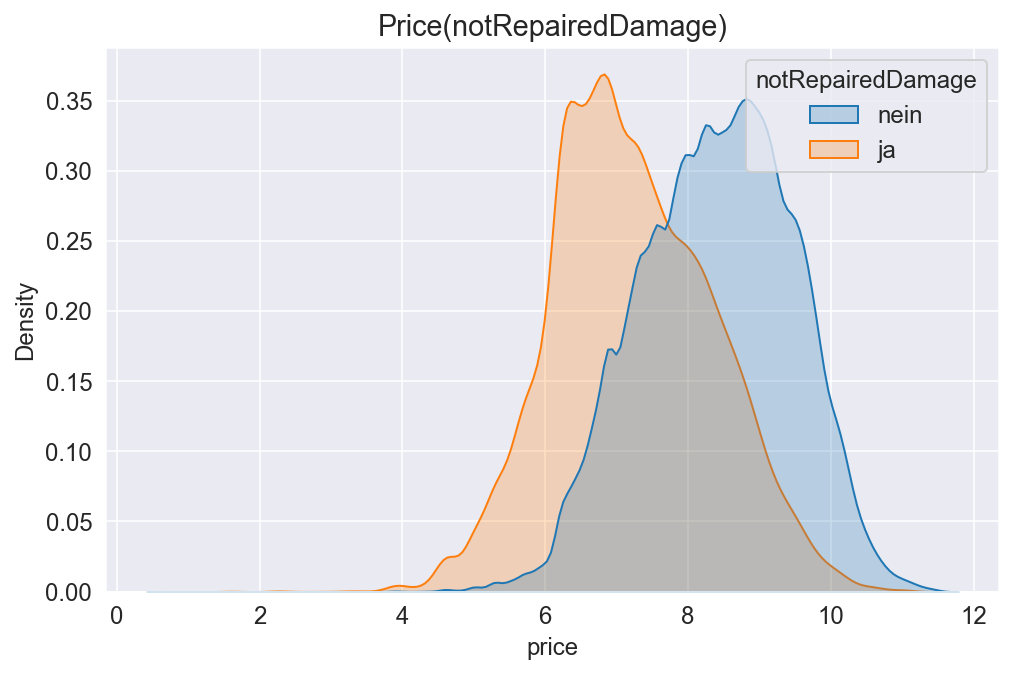

In [61]:
categorical_no_legend = ["brand", "model", "vehicleType", "fuelType"]
categorical_yes_legend = ["gearbox", "notRepairedDamage"]
for col in categorical_no_legend:
    plt.figure()
    sns.kdeplot(data=data, x="price", hue=col, common_norm=False, fill=True, legend=False)
    plt.title(f"Price({col})")
for col in categorical_yes_legend:
    plt.figure()
    sns.kdeplot(data=data, x="price", hue=col, common_norm=False, fill=True)
    plt.title(f"Price({col})")

Все категориальные признаки разделяют наше распределение на несколько несовпадающих нормальных (примерно нормальных), применить их можно, сделав OneHotEncoding (но brand и model могут слишком сильно раздуть количество параметров).

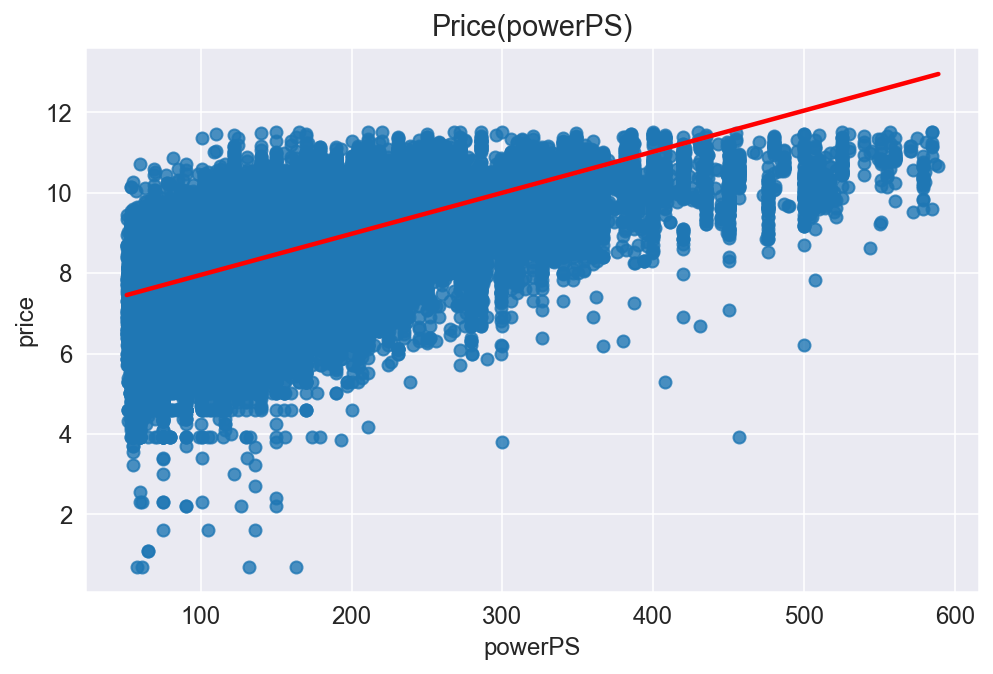

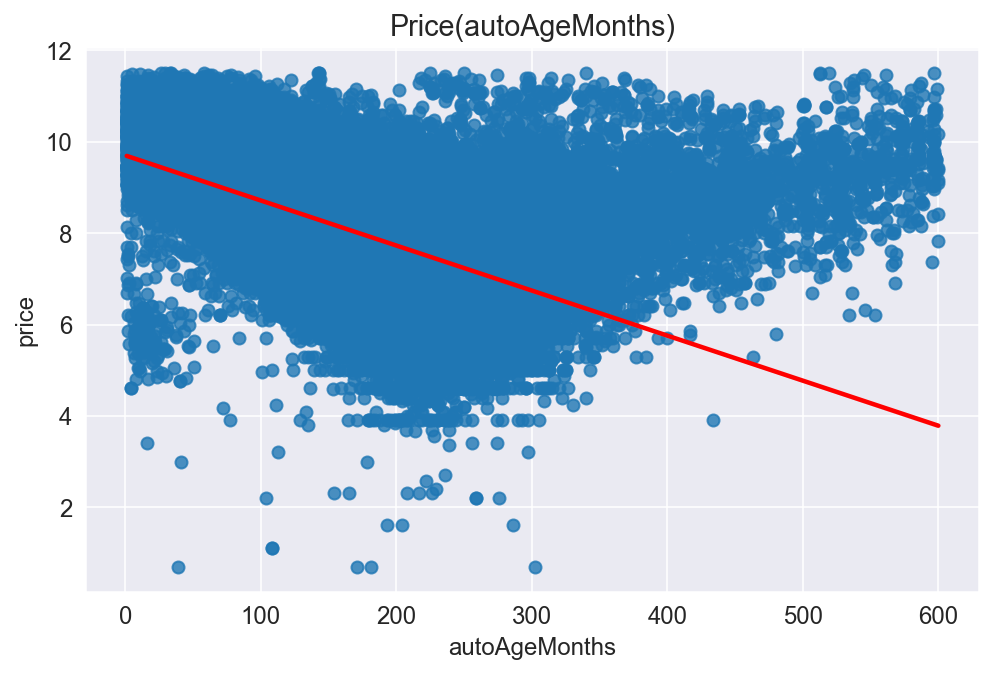

In [62]:
for col in ["powerPS", "autoAgeMonths"]:
    plt.figure()
    sns.regplot(data=data, x=col, y="price", line_kws={"color": "red"})
    plt.title(f"Price({col})")

Text(0.5, 1.0, 'Price(kilometer)')

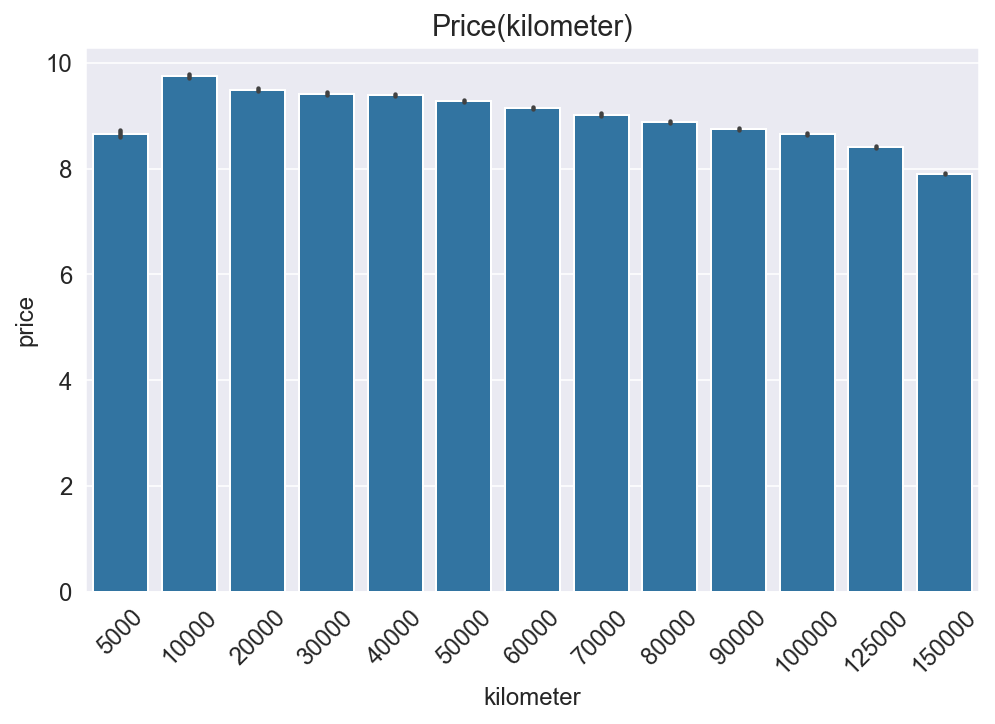

In [63]:
sns.barplot(data=data, x="kilometer", y="price")
plt.xticks(rotation=45)
plt.title("Price(kilometer)")

В целом powerPS, autoAgeMonts и kilometer применять логично, зависимость видна, но можно использовать бинаризацию этих признаков.

Добавляем в данные единичную колонку `bias`, чтобы не делать отдельные параметр $b$ для свободного члена модели.

In [21]:
data['bias'] = 1
other += ['bias']

In [22]:
X = data[categorical + numeric + other]
y = data['price'].to_numpy()

Теперь вам необходимо разбить данные на обучающую, тестовую и валидационную выборки.

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

(192729, 10) (24091, 10) (24092, 10)


А также сделаем базовую обработку данных, а именно:
* Применим `OneHotEncoding` к категориальным признакам
* Стандартизуем численные признаки с помощью `StandardScaler`
* Остальные признаки трогать не будем, т.к. с ними непонятно что делать

> А почему мы сначала делим данные, а только потом применяем обработку данных? Энкодеры и скейлеры используют информацию о данных: если сделать fit на всем датасете до split, это будет утечка: статистики из val/test попадут в обучение.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler


column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('scaling', StandardScaler(), numeric),
    ('other',  'passthrough', other)
])

X_train = column_transformer.fit_transform(X_train)
X_val = column_transformer.transform(X_val)
X_test = column_transformer.transform(X_test)

## Задание 5. Сравнение методов градиентного спуска (1.5 балла)

В этом задании вам предстоит сравнить методы градиентного спуска на подготовленных вами данных из предыдущего задания.

### Задание 5.1. Подбор оптимальной длины шага (0.75 балла)

Подберите по валидационной выборке наилучшую длину шага $\lambda$ для каждого метода с точки зрения ошибки. Для этого сделайте перебор по логарифмической сетке. Для каждого метода посчитайте ошибку на обучающей и тестовой выборках, посчитайте качество по метрике $R^2$, сохраните количество итераций до сходимости.

Все параметры кроме `lambda_` стоит выставить равным значениям по умолчанию.

In [71]:
descent_models = [
   VanillaGradientDescent,
   StochasticGradientDescent,
   SAGDescent,
   MomentumDescent,
   Adam
]
info_dict = {}

lambda_search = np.logspace(-4, 1, 11)
print(lambda_search)
for descent_model in descent_models:
    print(descent_model.__name__)
    info_dict[descent_model.__name__] = {}

    best_mse = float("inf")
    best_lambda = 0
    best_r_2 = -float("inf")
    best_iters = float("inf")
    best_loss_history = None
    best_test_mse = float("inf")
    
    for lambda_ in lambda_search:
        print(lambda_)
        optimizer = descent_model(lr_schedule=TimeDecayLR(lambda_=lambda_))
        model = CustomLinearRegression(optimizer=optimizer)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        mse_val = np.mean((y_pred - y_val) ** 2)
        if mse_val < best_mse:
            best_mse = mse_val
            best_lambda = lambda_
            best_r_2 = 1 - (np.sum((y_val - y_pred) ** 2)) / np.sum((y_val - np.mean(y_val)) ** 2)
            best_iters = model.optimizer.iteration
            best_loss_history = model.loss_history
            best_test_mse = np.mean((model.predict(X_test) - y_test) ** 2)

    info_dict[descent_model.__name__]["best_lambda"] = best_lambda
    info_dict[descent_model.__name__]["best_mse"] = best_mse
    info_dict[descent_model.__name__]["r_2"] = best_r_2
    info_dict[descent_model.__name__]["iters"] = best_iters
    info_dict[descent_model.__name__]["loss_history"] = best_loss_history
    info_dict[descent_model.__name__]["test_mse"] = best_test_mse
    

print(pd.DataFrame(info_dict).T)

[1.00000000e-04 3.16227766e-04 1.00000000e-03 3.16227766e-03
 1.00000000e-02 3.16227766e-02 1.00000000e-01 3.16227766e-01
 1.00000000e+00 3.16227766e+00 1.00000000e+01]
VanillaGradientDescent
0.0001
0.00031622776601683794
0.001
0.0031622776601683794
0.01
0.03162277660168379
0.1
0.31622776601683794
1.0
3.1622776601683795
10.0


c:\Users\grach\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\core\_methods.py:118: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
c:\Users\grach\Documents\GitHub\ai360_research\homework-practice\homework-practice-02-gd\linear_regression.py:29: RuntimeWarning: overflow encountered in square
  return np.mean((X @ w - y) ** 2)
c:\Users\grach\Documents\GitHub\ai360_research\homework-practice\homework-practice-02-gd\descents.py:88: RuntimeWarning: invalid value encountered in add
  self.model.w += delta


StochasticGradientDescent
0.0001
0.00031622776601683794
0.001
0.0031622776601683794
0.01
0.03162277660168379
0.1
0.31622776601683794
1.0
3.1622776601683795
10.0


c:\Users\grach\Documents\GitHub\ai360_research\homework-practice\homework-practice-02-gd\descents.py:109: RuntimeWarning: invalid value encountered in add
  self.model.w += delta


SAGDescent
0.0001
0.00031622776601683794
0.001
0.0031622776601683794
0.01
0.03162277660168379
0.1
0.31622776601683794
1.0
3.1622776601683795
10.0
MomentumDescent
0.0001
0.00031622776601683794
0.001
0.0031622776601683794
0.01
0.03162277660168379
0.1
0.31622776601683794
1.0
3.1622776601683795
10.0


C:\Users\grach\AppData\Local\Temp\ipykernel_27352\209168163.py:29: RuntimeWarning: overflow encountered in square
  mse_val = np.mean((y_pred - y_val) ** 2)


Adam
0.0001
0.00031622776601683794
0.001
0.0031622776601683794
0.01
0.03162277660168379
0.1
0.31622776601683794
1.0
3.1622776601683795
10.0
                          best_lambda  best_mse       r_2 iters  \
VanillaGradientDescent            1.0  0.300878  0.761147   394   
StochasticGradientDescent    0.316228  0.323999  0.742792  1000   
SAGDescent                        1.0  1.442816 -0.145385  1000   
MomentumDescent                   1.0  0.278031  0.779284   799   
Adam                         3.162278  0.273667  0.782748  1000   

                                                                loss_history  \
VanillaGradientDescent     [69.7359585061274, 2185.9465570852703, 30676.6...   
StochasticGradientDescent  [69.7359585061274, 93.8962597191411, 29.012946...   
SAGDescent                 [69.7359585061274, 69.59156645376899, 69.38999...   
MomentumDescent            [69.7359585061274, 2185.9465570852703, 15822.5...   
Adam                       [69.7359585061274, 225.1229093

In [72]:
pd.DataFrame(info_dict).T

,best_lambda,best_mse,r_2,iters,loss_history,test_mse
VanillaGradientDescent,1.0,0.300878,0.761147,394,"[69.7359585061274, 2185.9465570852703, 30676.6...",0.3061
StochasticGradientDescent,0.316228,0.323999,0.742792,1000,"[69.7359585061274, 93.8962597191411, 29.012946...",0.330517
SAGDescent,1.0,1.442816,-0.145385,1000,"[69.7359585061274, 69.59156645376899, 69.38999...",1.459771
MomentumDescent,1.0,0.278031,0.779284,799,"[69.7359585061274, 2185.9465570852703, 15822.5...",0.279967
Adam,3.162278,0.273667,0.782748,1000,"[69.7359585061274, 225.12290933484502, 93.4397...",0.273488


### Задание 5.2. Сравнение методов (0.75 балла)

Постройте график зависимости ошибки на обучающей выборке от номера итерации (все методы на одном графике).

Посмотрите на получившиеся результаты (таблички с метриками и график). Сравните методы между собой.

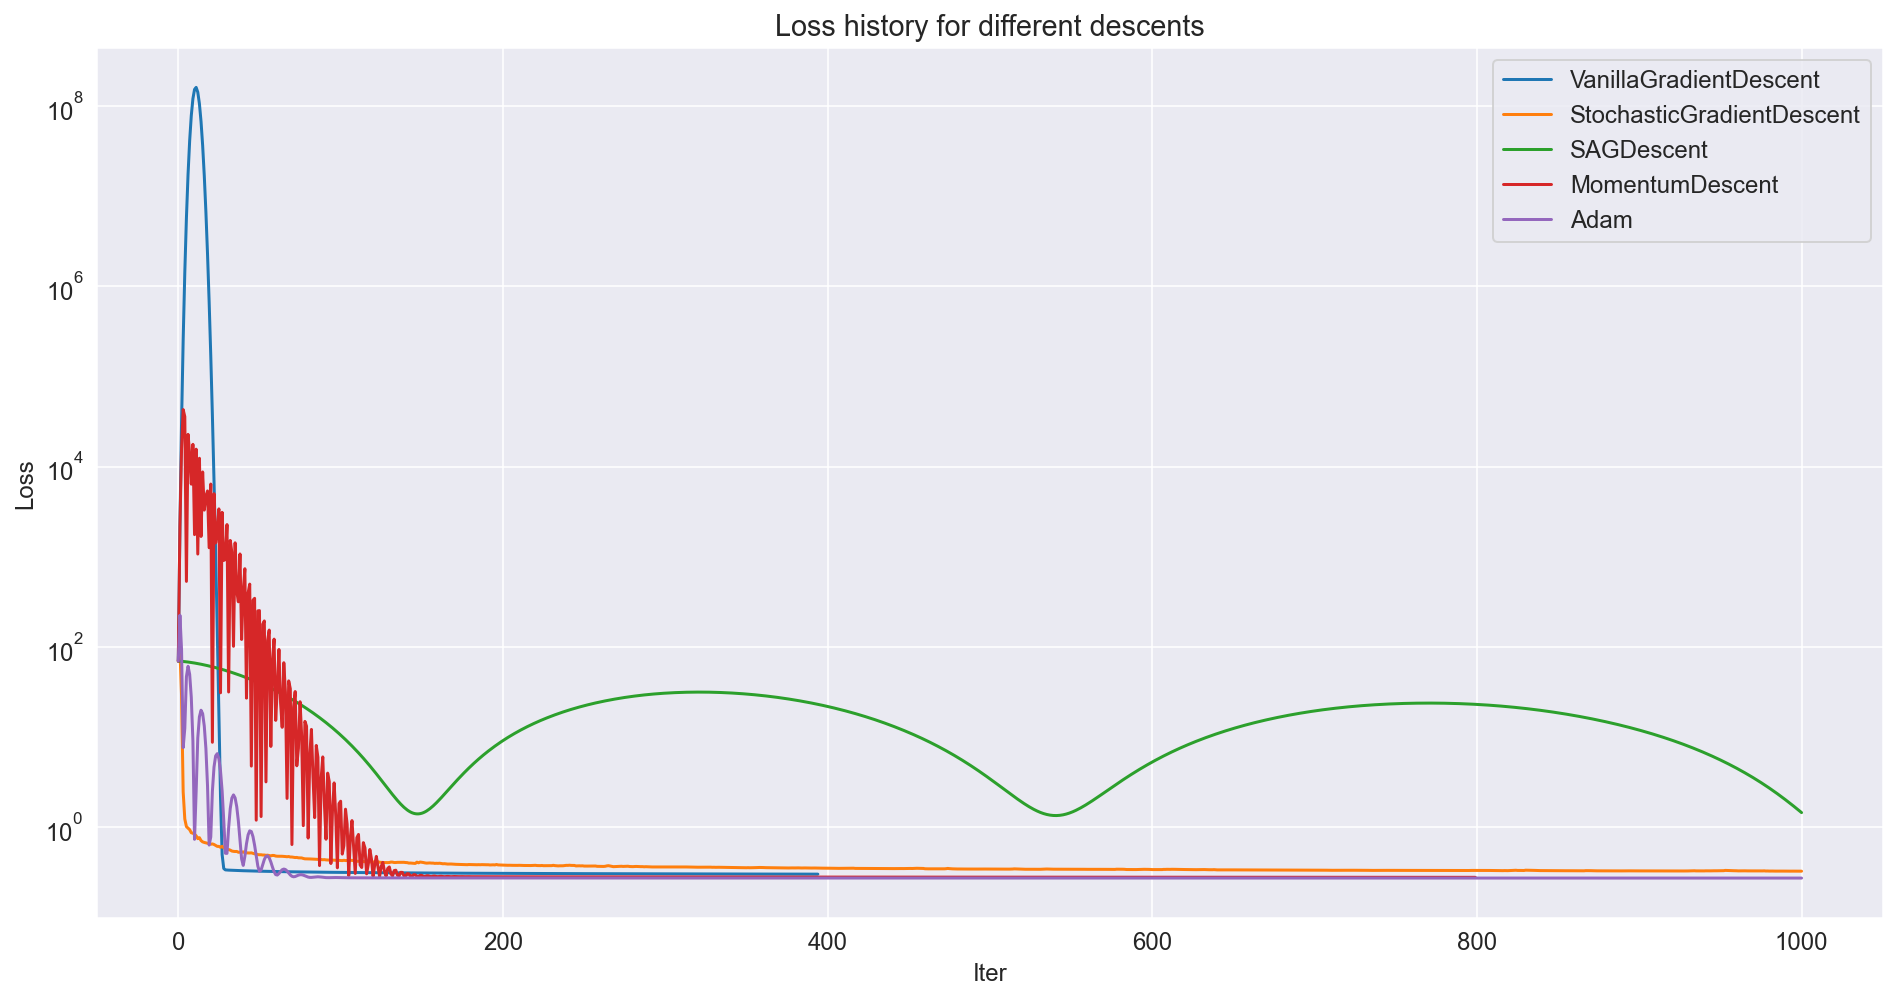

In [82]:
plt.figure(figsize=(16, 8))
for descent_model in descent_models:
    plt.yscale("log")
    plt.plot(info_dict[descent_model.__name__]["loss_history"], label=descent_model.__name__)
plt.title("Loss history for different descents")
plt.xlabel("Iter")
plt.ylabel("Loss")
plt.legend()

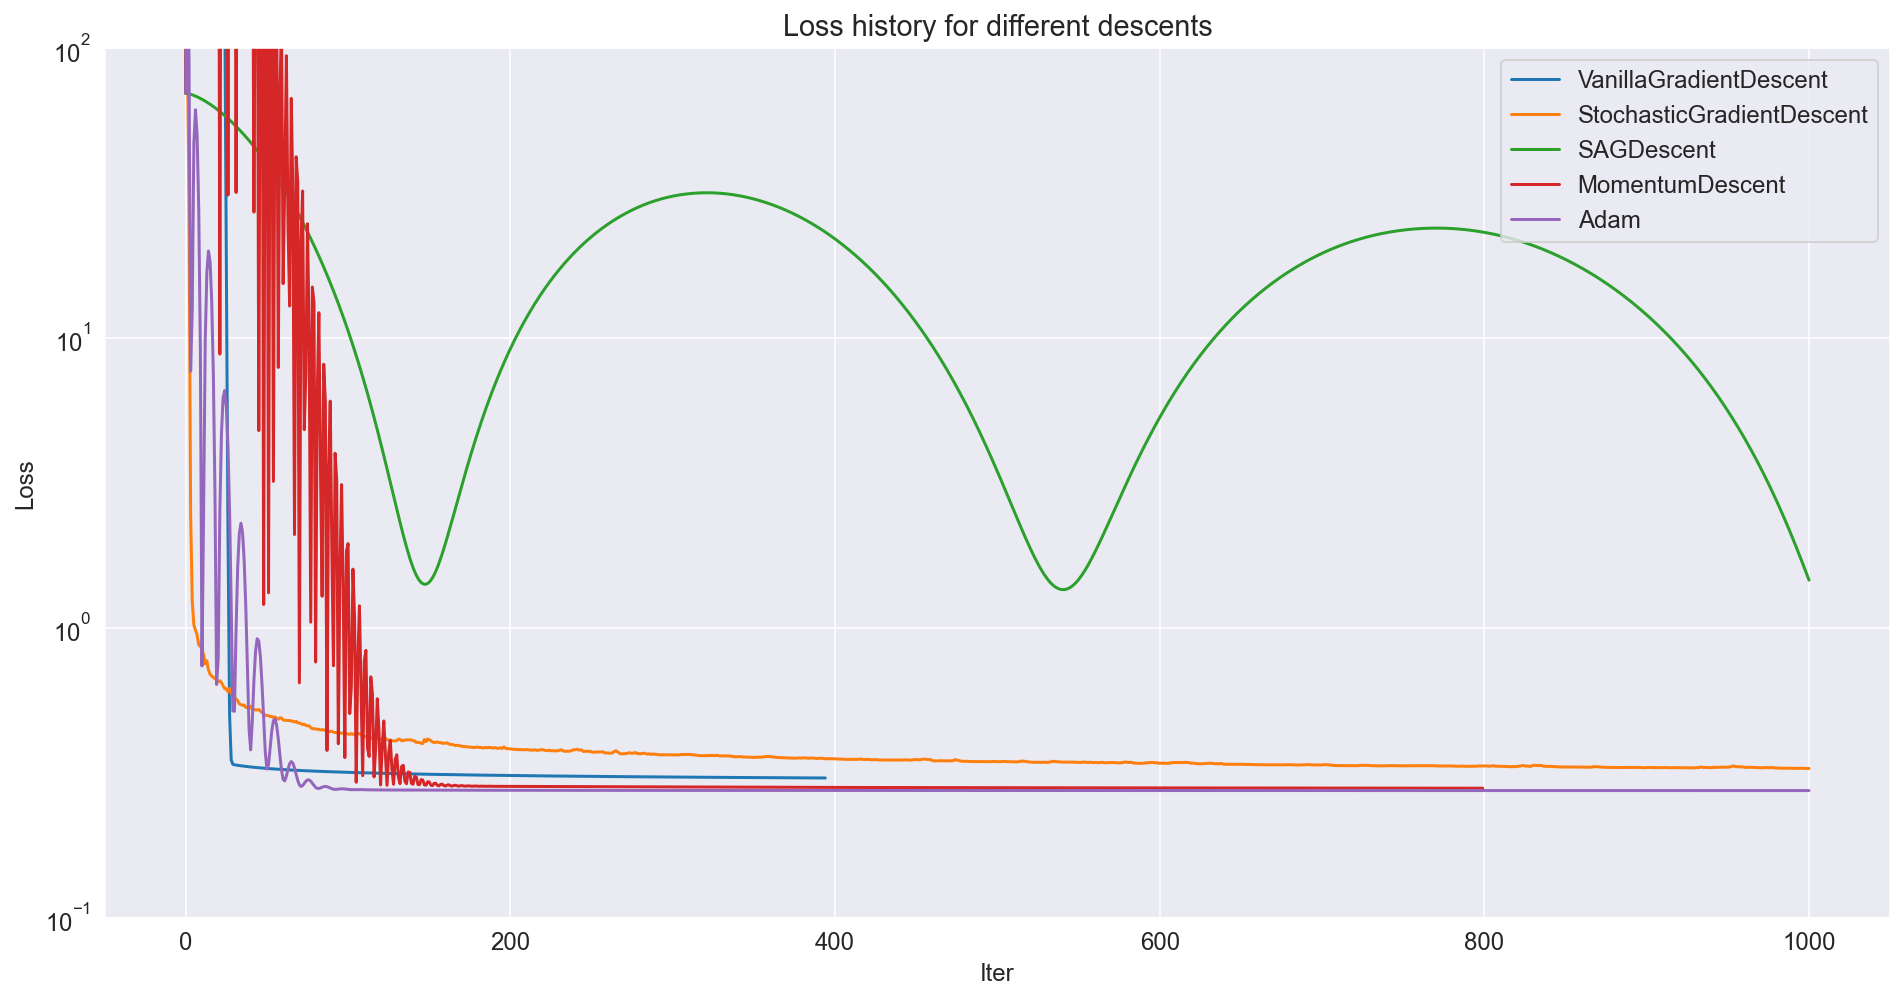

In [83]:
plt.figure(figsize=(16, 8))
plt.ylim(1e-1, 1e2)
for descent_model in descent_models:
    plt.yscale("log")
    plt.plot(info_dict[descent_model.__name__]["loss_history"], label=descent_model.__name__)
plt.title("Loss history for different descents")
plt.xlabel("Iter")
plt.ylabel("Loss")
plt.legend()

С точки зрения адекватности побеждают Adam и SGD. Достаточно быстро (к 100-ой итерации) получают хороший лосс, который потом стабилизируется.

Но Adam, в отличие от SGD сходится со всплесками (возможно из-за большого lr).

Лосс Vanilla сначала улетает вверх, вероятно, из-за большого начального значения lr. Потом после его уменьшения, падает и лосс.

Momentum имеет ещё больше всплесков, чем Adam, сходится медленнее него.

Проблемы у SAG из-за медленного обновления: так как batch size = 32, итераций 1000, а элементов десятки тысяч.

По лоссу все, кроме SAG дают похожие результаты, лучше всего себя показывают momentum и adam. SAG работает даже хуже константного предсказания среднего из-за вышеописанной проблемы.


## Задание 6. Стохастический градиентный спуск и размер батча (1 балл)

В этом задании вам предстоит исследовать влияние размера батча на работу стохастического градиентного спуска.

* Сделайте по несколько запусков (например, $k = 10$) стохастического градиентного спуска на обучающей выборке для каждого размера батча из перебираемого списка. Замерьте время в секундах и количество итераций до сходимости. Посчитайте среднее этих значений для каждого размера батча.
* Постройте график зависимости количества шагов до сходимости от размера батча. _(под сходимостью понимается достижение критерия останова)_
* Постройте график зависимости времени до сходимости от размера батча.

Посмотрите на получившиеся результаты. Какие выводы можно сделать про подбор размера батча для стохастического градиентного спуска?

In [66]:
import time

sgd_batch_sizes = [1, 32, 128, 512, 2048, 8192, 32768, 65536]
sgd_info_dicts = []
sgd_runs = 5
for batch_size in sgd_batch_sizes:
    time_ = 0
    iters_ = 0
    mse_val_ = 0
    for run in range(sgd_runs):
        optimizer = StochasticGradientDescent(lr_schedule=TimeDecayLR(lambda_=info_dict["StochasticGradientDescent"]["best_lambda"]), max_iter=10000, batch_size=batch_size)
        model = CustomLinearRegression(optimizer=optimizer)

        start = time.perf_counter() 
        model.fit(X_train, y_train)
        end = time.perf_counter()
        
        y_pred = model.predict(X_val)
        mse_val = np.mean((y_pred - y_val) ** 2)

        time_ += end - start
        iters_ += model.optimizer.iteration
        mse_val_ += mse_val

    time_ /= sgd_runs
    iters_ /= sgd_runs
    mse_val_ /= sgd_runs

    sgd_info_dicts.append({"batch_size": batch_size, "time": time_, "iters": iters_, "mse": mse_val_})
    print(f"Batch size: {batch_size}, Time: {time_}, Iters: {iters_}, MSE: {mse_val_}")

Batch size: 1, Time: 3.8240853999741375, Iters: 584.6, MSE: 57.736805304898006
Batch size: 32, Time: 26.797391180042176, Iters: 4101.2, MSE: 0.30433084496453444
Batch size: 128, Time: 15.437764579989016, Iters: 2354.0, MSE: 0.30581722715776377
Batch size: 512, Time: 6.322824079962447, Iters: 959.4, MSE: 0.31492095658174
Batch size: 2048, Time: 3.0838664199924097, Iters: 456.8, MSE: 0.32444436147236494
Batch size: 8192, Time: 2.6058239799924197, Iters: 346.6, MSE: 0.3288889080699759
Batch size: 32768, Time: 3.839547139988281, Iters: 332.8, MSE: 0.3296653113633205
Batch size: 65536, Time: 5.456015039957128, Iters: 327.8, MSE: 0.32987265454103615


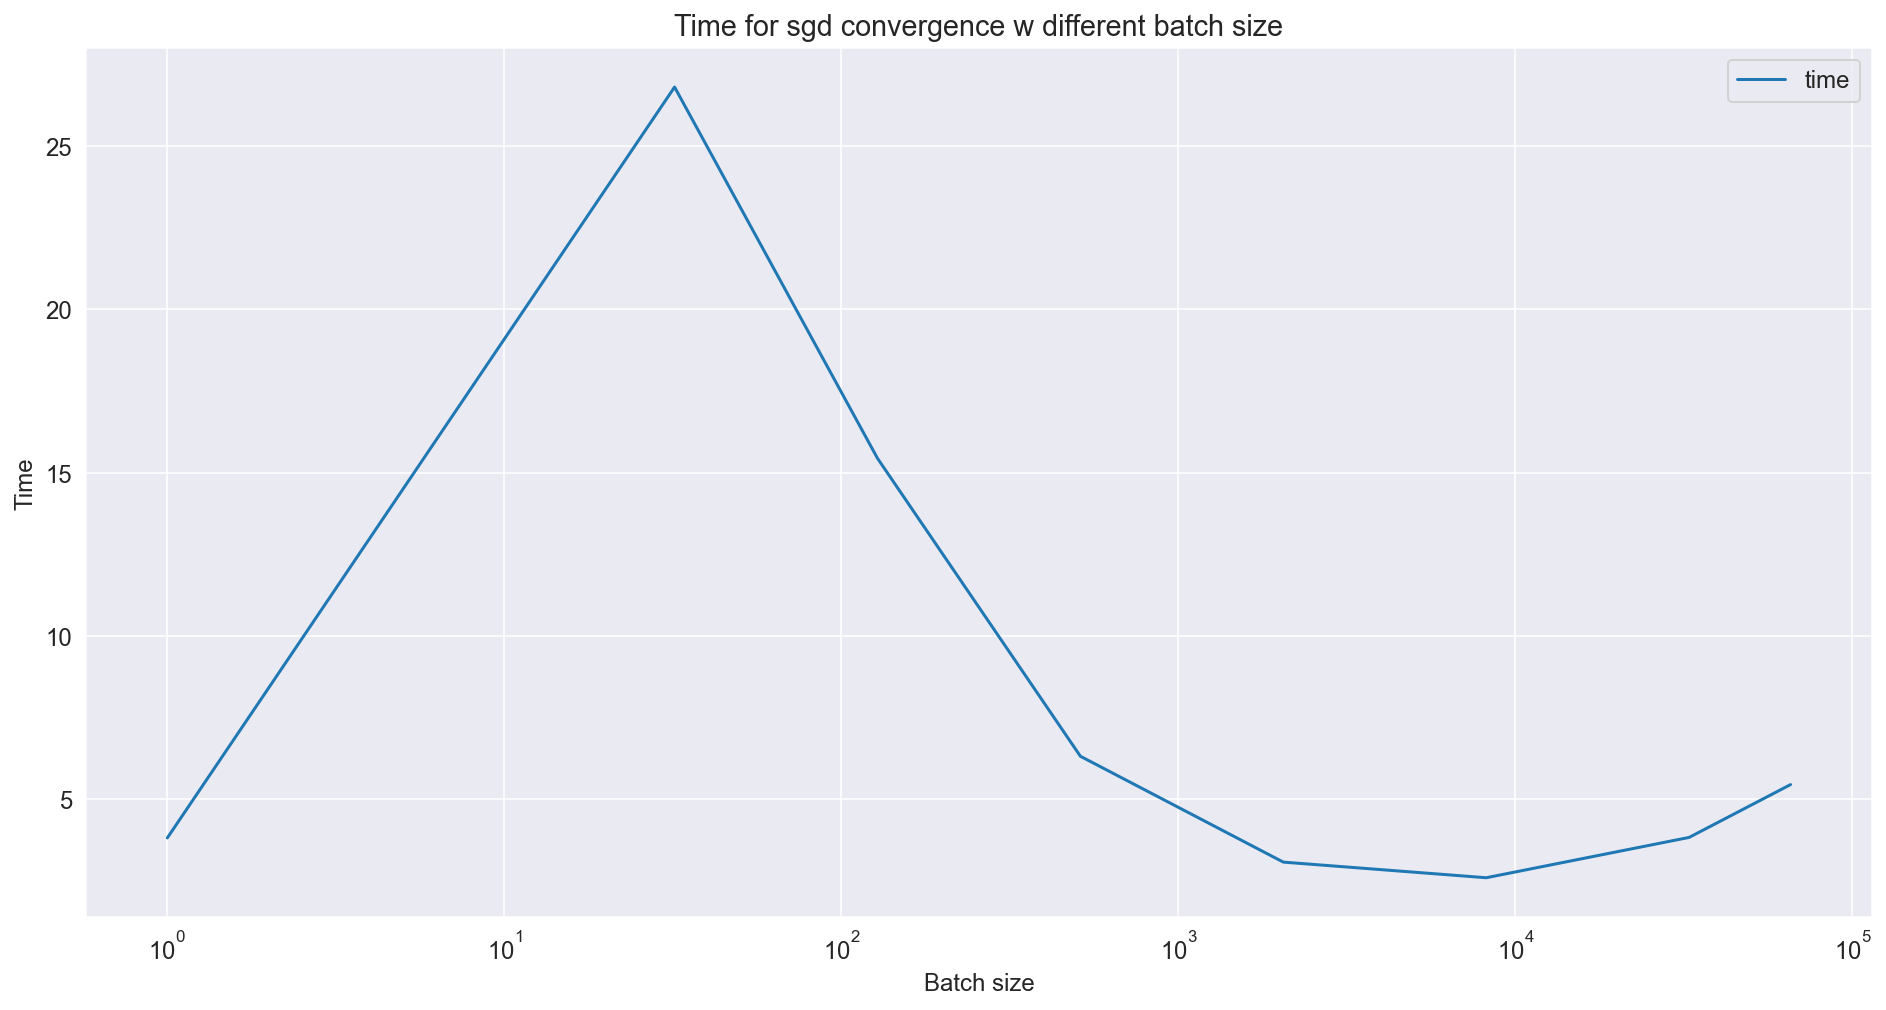

In [69]:
plt.figure(figsize=(16, 8))
plt.plot(sgd_batch_sizes, [sgd_info_dicts[i]["time"] for i in range(len(sgd_info_dicts))], label="time")
plt.xscale("log")
plt.xlabel("Batch size")
plt.ylabel("Time")
plt.title("Time for sgd convergence w different batch size")
plt.legend()

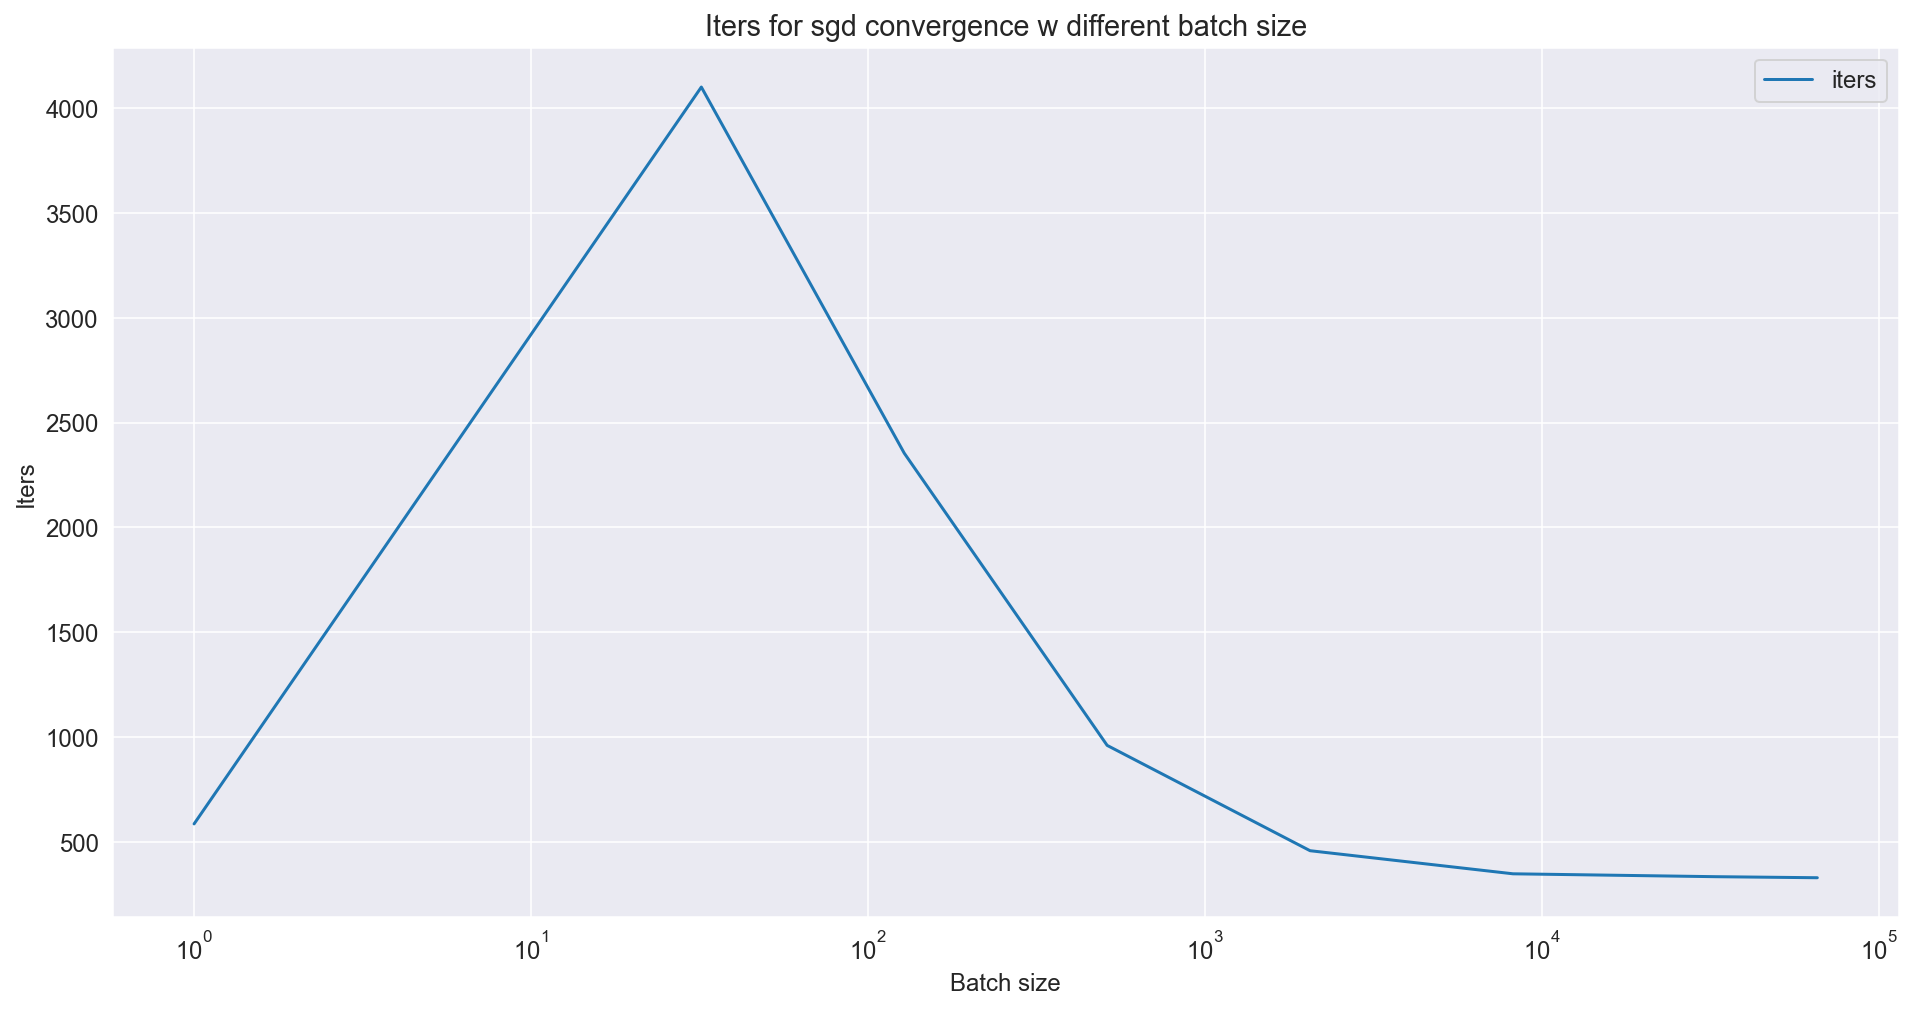

In [70]:
plt.figure(figsize=(16, 8))
plt.plot(sgd_batch_sizes, [sgd_info_dicts[i]["iters"] for i in range(len(sgd_info_dicts))], label="iters")
plt.xscale("log")
plt.xlabel("Batch size")
plt.ylabel("Iters")
plt.title("Iters for sgd convergence w different batch size")
plt.legend()

**Выводы:**
Здесь получилось, что для batch size 1 метод сошелся быстро, но не к желаемому минимуму, и лосс там значительно выше.

Batch size можно подбирать по валидационной выборке, чтобы получить желаемую скорость сходимости. Например, простым перебором, как здесь мы сделали. По графикам мы видим, что это вообще не линейная история.

Чем больше делать batch size, тем меньше итераций должно потребоваться для сходимости. Но вот на скорость он влияет нелинейно, и с некоторого момента увеличение batch size нас замедляет.

## Задание 7. Регуляризация (0.5 балла)

В этом задании вам предстоит исследовать влияние регуляризации на работу различных методов градиентного спуска. Напомним, регуляризация – это добавка к функции потерь, которая штрафует за норму весов. Мы будем использовать $L_2$-регуляризацию, таким образом функция потерь приобретает следующий вид:

$$
    Q(w) = \dfrac{1}{\ell} \sum\limits_{i=1}^{\ell} (a_w(x_i) - y_i)^2 + \dfrac{\mu}{2} \| w \|^2
$$

Допишите класс `linear_regression.L2Regularization`, следуя интерфейсу и докуметации.

Используя регуляризованный лосс в эксприментах, найдите лучшие параметры обучения с регуляризацией аналогично 5 заданию. Будем подбирать длину шага $\lambda$ (`lambda_`) и коэффициент регуляризации $\mu$ (`mu`).

Сравните для каждого метода результаты с регуляризацией и без регуляризации (нужно опять сохранить ошибку и качество по метрике $R^2$ на обучающей и тестовой выборках и количество итераций до сходимости).

Постройте для каждого метода график со значениями функции потерь MSE с регуляризацией и без регуляризации (всего должно получиться 5 графиков).

Посмотрите на получившиеся результаты. Какие можно сделать выводы, как регуляризация влияет на сходимость? Как изменилось качество на обучающей выборке? На тестовой? Чем вы можете объяснить это?

In [101]:
from linear_regression import L2Regularization

info_dict_reg = {}
mu_results = {}

lambda_search = np.logspace(-4, 1, 11)
mu_search = [0.1, 0.3, 1]

print(lambda_search)
for descent_model in descent_models:
    print(descent_model.__name__)
    info_dict_reg [descent_model.__name__] = {}

    best_mse = float("inf")
    best_lambda = 0
    best_mu = 0
    best_r_2 = -float("inf")
    best_iters = float("inf")
    best_loss_history = None
    best_test_mse = float("inf")
        
    for mu_rate in mu_search:
        print(mu_rate)
        best_mse_mu = float("inf")
        for lambda_ in lambda_search:
            optimizer = descent_model(lr_schedule=TimeDecayLR(lambda_=lambda_))
            regularization = L2Regularization(mu_rate=mu_rate, core_loss=MSELoss())
            model = CustomLinearRegression(optimizer=optimizer, loss_function=regularization)
            model.fit(X_train, y_train)
            y_pred = model.predict(X_val)
            mse_val = np.mean((y_pred - y_val) ** 2)

            if mse_val < best_mse:
                best_mse = mse_val
                best_lambda = lambda_
                best_mu = mu_rate
                best_r_2 = 1 - (np.sum((y_val - y_pred) ** 2)) / np.sum((y_val - np.mean(y_val)) ** 2)
                best_iters = model.optimizer.iteration
                best_loss_history = model.loss_history
                best_test_mse = np.mean((model.predict(X_test) - y_test) ** 2)
            best_mse_mu = min(best_mse_mu, mse_val)
            mu_results[(descent_model.__name__, mu_rate)] = best_mse_mu

    info_dict_reg[descent_model.__name__]["best_lambda"] = best_lambda
    info_dict_reg[descent_model.__name__]["best_mse"] = best_mse
    info_dict_reg[descent_model.__name__]["best_mu"] = best_mu
    info_dict_reg[descent_model.__name__]["r_2"] = best_r_2
    info_dict_reg[descent_model.__name__]["iters"] = best_iters
    info_dict_reg[descent_model.__name__]["loss_history"] = best_loss_history
    info_dict_reg[descent_model.__name__]["test_mse"] = best_test_mse

[1.00000000e-04 3.16227766e-04 1.00000000e-03 3.16227766e-03
 1.00000000e-02 3.16227766e-02 1.00000000e-01 3.16227766e-01
 1.00000000e+00 3.16227766e+00 1.00000000e+01]
VanillaGradientDescent
0.1


c:\Users\grach\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\core\_methods.py:118: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
c:\Users\grach\Documents\GitHub\ai360_research\homework-practice\homework-practice-02-gd\linear_regression.py:29: RuntimeWarning: overflow encountered in square
  return np.mean((X @ w - y) ** 2)
c:\Users\grach\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\core\_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\grach\Documents\GitHub\ai360_research\homework-practice\homework-practice-02-gd\linear_regression.py:97: RuntimeWarning: overflow encountered in square
  return self.core_loss.loss(X, y, w) + 0.5 * self.mu_rate * (w_pen ** 2).sum()
C:\Users\grach\AppData\Local\Temp\ipykernel_27352\1292422610.py:31: RuntimeWarning: overflow encountered in square
  mse_val = np.mean((y_pred

0.3
1
StochasticGradientDescent
0.1
0.3
1
SAGDescent
0.1
0.3
1
MomentumDescent
0.1
0.3
1
Adam
0.1
0.3
1


In [102]:
pd.DataFrame(info_dict_reg).T

,best_lambda,best_mse,best_mu,r_2,iters,loss_history,test_mse
VanillaGradientDescent,3.162278,0.491127,0.1,0.610117,1000,"[69.7359585061274, 13279.1841009142, 1287791.7...",0.496481
StochasticGradientDescent,0.316228,0.498559,0.1,0.604217,1000,"[69.7359585061274, 20.82321004845093, 3.484459...",0.503338
SAGDescent,10.0,3.446828,1,-1.736277,1000,"[69.7359585061274, 68.74714877533091, 67.33807...",3.42191
MomentumDescent,1.0,0.492654,0.1,0.608905,1000,"[69.7359585061274, 957.52244003328, 1643.55702...",0.497825
Adam,1.0,0.492654,0.1,0.608905,1000,"[69.7359585061274, 22.53817917773482, 13.90905...",0.497825


In [103]:
mu_results

{('VanillaGradientDescent', 0.1): 0.4911266140593468,
 ('VanillaGradientDescent', 0.3): 0.9963910050477047,
 ('VanillaGradientDescent', 1): 3.3938804499883037,
 ('StochasticGradientDescent', 0.1): 0.4985589838000886,
 ('StochasticGradientDescent', 0.3): 1.0037434845091986,
 ('StochasticGradientDescent', 1): 3.402179948970027,
 ('SAGDescent', 0.1): 5.077325070220402,
 ('SAGDescent', 0.3): 8.39680879136271,
 ('SAGDescent', 1): 3.446828017675204,
 ('MomentumDescent', 0.1): 0.4926542005569622,
 ('MomentumDescent', 0.3): 0.9963910050470927,
 ('MomentumDescent', 1): 3.393880449988302,
 ('Adam', 0.1): 0.49265410109348673,
 ('Adam', 0.3): 0.9963756003576103,
 ('Adam', 1): 3.3938804499883033}

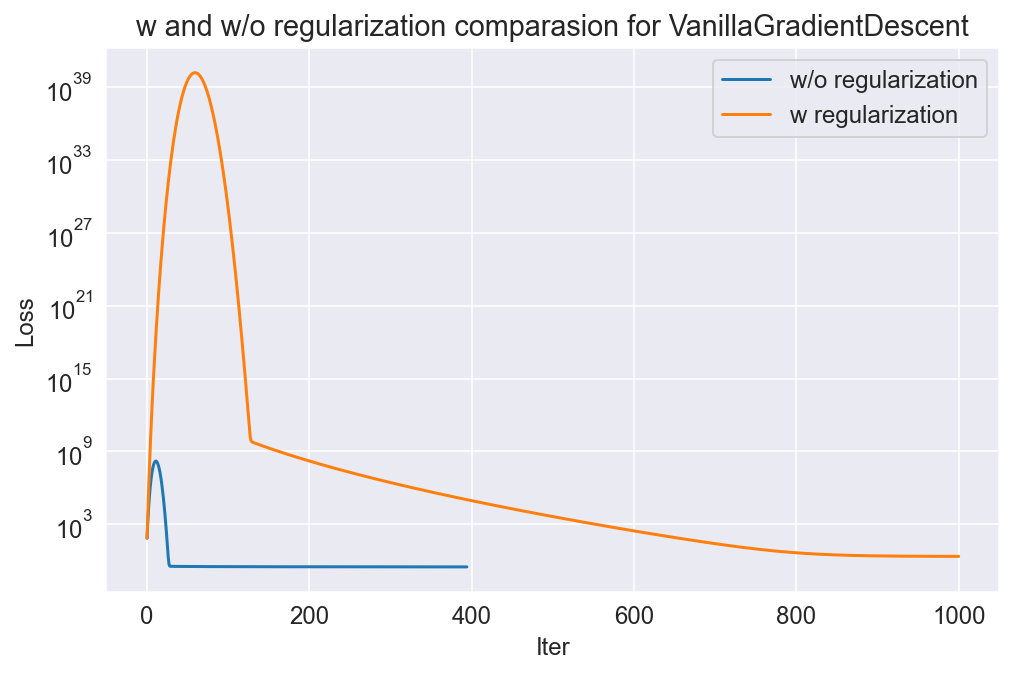

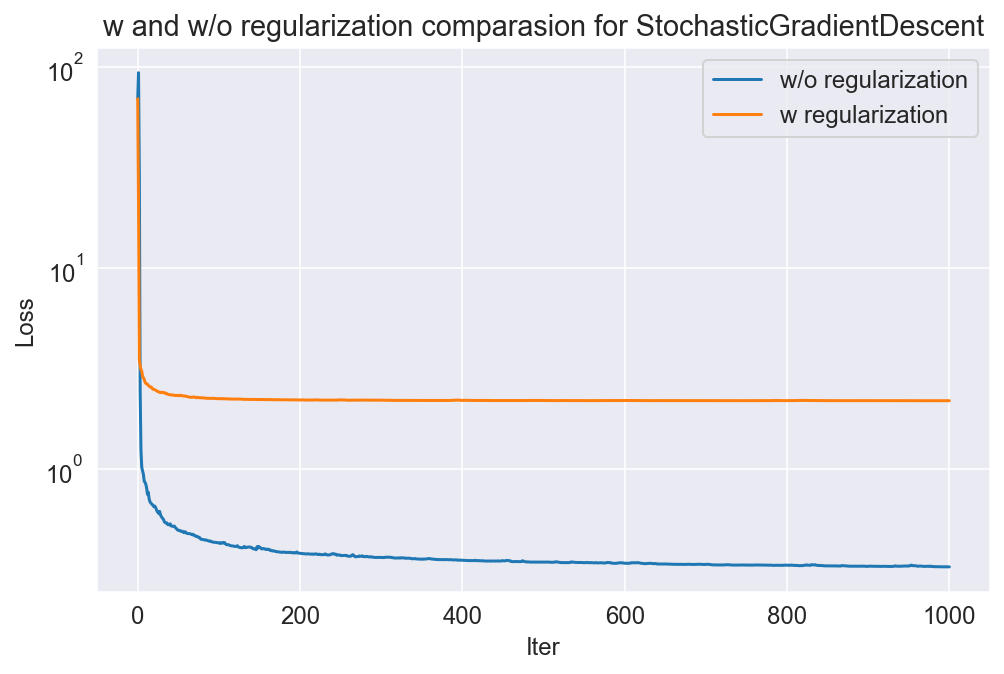

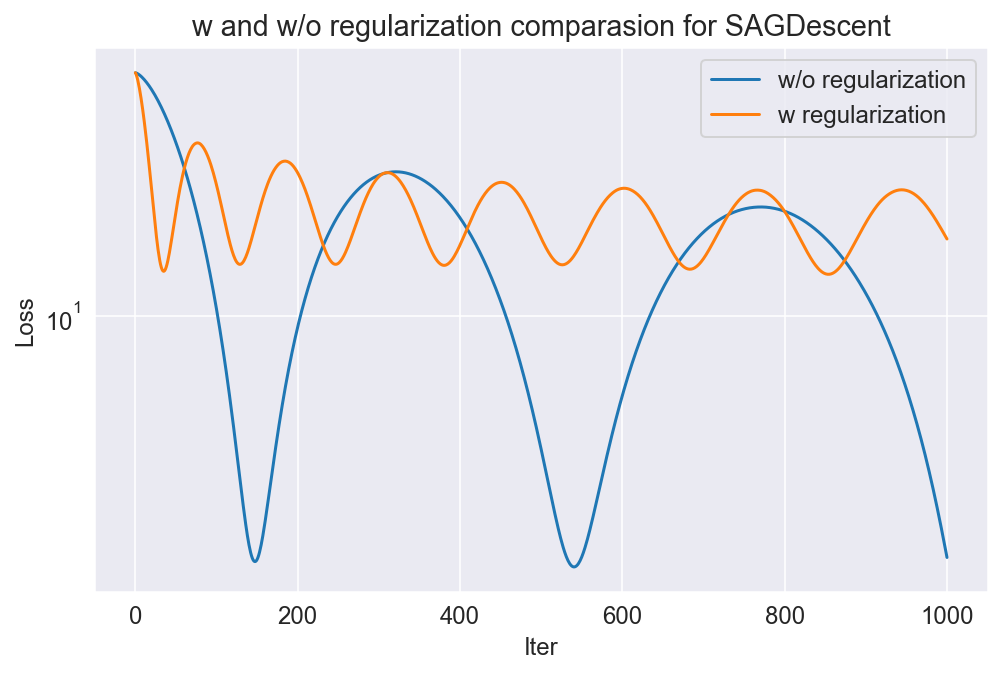

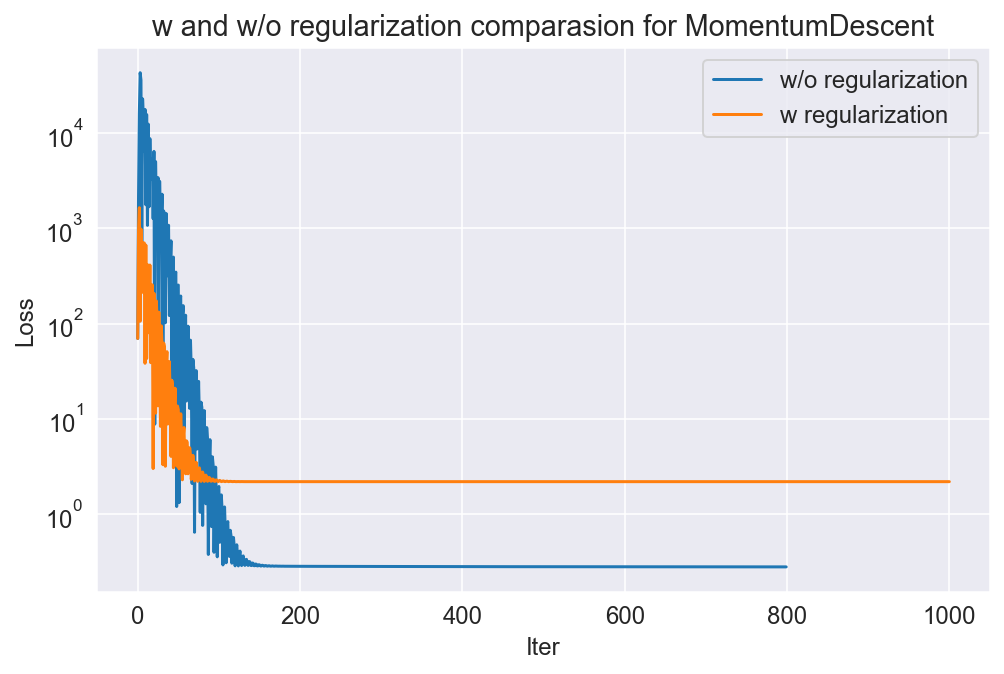

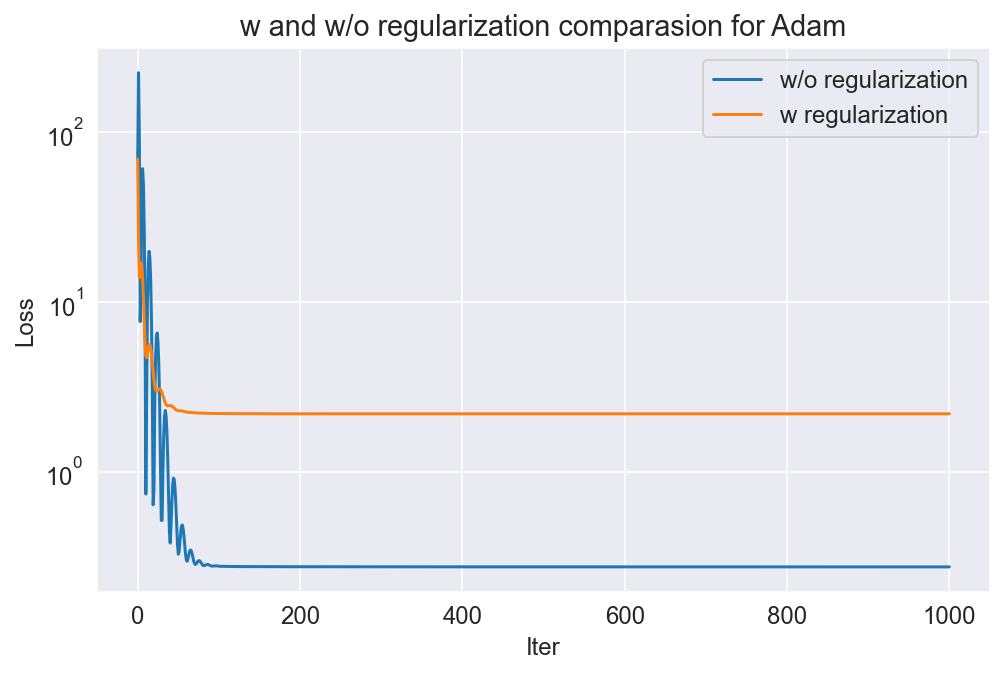

In [105]:
for descent_model in descent_models:
    plt.figure()
    plt.title(f"w and w/o regularization comparasion for {descent_model.__name__}")
    plt.plot(info_dict[descent_model.__name__]["loss_history"], label="w/o regularization")
    plt.plot(info_dict_reg[descent_model.__name__]["loss_history"], label="w regularization")
    plt.yscale("log")
    plt.xlabel("Iter")
    plt.ylabel("Loss")
    plt.legend()

**Вывод:**

мы видим, что в данном случае регуляризация значительно ухудшила все методы (качество падает и на обучающей и на тестовой выборках). Вместо 0.3 loss на четырех методах стало 0.5, на SAG тоже хуже. Сходимость замедлилась.

Поскольку мы меняем лосс, новая точка оптимума сдвигается, поэтому найденное с регуляризацией решение будет находиться дальше от решения без регуляризации, и ожидаемо результат будет хуже.

С регуляризацией momentum и adam учатся плавнее (меньше колеблется лосс в процессе обучения).

In [106]:
from linear_regression import L2Regularization

info_dict_reg = {}
mu_results = {}

lambda_search = np.logspace(-4, 1, 11)
mu_search = [0.01]

print(lambda_search)
for descent_model in descent_models:
    print(descent_model.__name__)
    info_dict_reg [descent_model.__name__] = {}

    best_mse = float("inf")
    best_lambda = 0
    best_mu = 0
    best_r_2 = -float("inf")
    best_iters = float("inf")
    best_loss_history = None
    best_test_mse = float("inf")
        
    for mu_rate in mu_search:
        print(mu_rate)
        best_mse_mu = float("inf")
        for lambda_ in lambda_search:
            optimizer = descent_model(lr_schedule=TimeDecayLR(lambda_=lambda_))
            regularization = L2Regularization(mu_rate=mu_rate, core_loss=MSELoss())
            model = CustomLinearRegression(optimizer=optimizer, loss_function=regularization)
            model.fit(X_train, y_train)
            y_pred = model.predict(X_val)
            mse_val = np.mean((y_pred - y_val) ** 2)

            if mse_val < best_mse:
                best_mse = mse_val
                best_lambda = lambda_
                best_mu = mu_rate
                best_r_2 = 1 - (np.sum((y_val - y_pred) ** 2)) / np.sum((y_val - np.mean(y_val)) ** 2)
                best_iters = model.optimizer.iteration
                best_loss_history = model.loss_history
                best_test_mse = np.mean((model.predict(X_test) - y_test) ** 2)
            best_mse_mu = min(best_mse_mu, mse_val)
            mu_results[(descent_model.__name__, mu_rate)] = best_mse_mu

    info_dict_reg[descent_model.__name__]["best_lambda"] = best_lambda
    info_dict_reg[descent_model.__name__]["best_mse"] = best_mse
    info_dict_reg[descent_model.__name__]["best_mu"] = best_mu
    info_dict_reg[descent_model.__name__]["r_2"] = best_r_2
    info_dict_reg[descent_model.__name__]["iters"] = best_iters
    info_dict_reg[descent_model.__name__]["loss_history"] = best_loss_history
    info_dict_reg[descent_model.__name__]["test_mse"] = best_test_mse

[1.00000000e-04 3.16227766e-04 1.00000000e-03 3.16227766e-03
 1.00000000e-02 3.16227766e-02 1.00000000e-01 3.16227766e-01
 1.00000000e+00 3.16227766e+00 1.00000000e+01]
VanillaGradientDescent
0.01


c:\Users\grach\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\core\_methods.py:118: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
c:\Users\grach\Documents\GitHub\ai360_research\homework-practice\homework-practice-02-gd\linear_regression.py:29: RuntimeWarning: overflow encountered in square
  return np.mean((X @ w - y) ** 2)
c:\Users\grach\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\core\_methods.py:49: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\grach\Documents\GitHub\ai360_research\homework-practice\homework-practice-02-gd\linear_regression.py:97: RuntimeWarning: overflow encountered in square
  return self.core_loss.loss(X, y, w) + 0.5 * self.mu_rate * (w_pen ** 2).sum()
C:\Users\grach\AppData\Local\Temp\ipykernel_27352\1916420589.py:31: RuntimeWarning: overflow encountered in square
  mse_val = np.mean((y_pred

StochasticGradientDescent
0.01
SAGDescent
0.01
MomentumDescent
0.01
Adam
0.01


In [107]:
pd.DataFrame(info_dict_reg).T

,best_lambda,best_mse,best_mu,r_2,iters,loss_history,test_mse
VanillaGradientDescent,1.0,0.310237,0.01,0.753717,1000,"[69.7359585061274, 929.0156888033154, 5231.561...",0.315247
StochasticGradientDescent,0.316228,0.348804,0.01,0.7231,1000,"[69.7359585061274, 22.997410135250774, 2.27152...",0.352848
SAGDescent,10.0,4.269678,0.01,-2.389499,1000,"[69.7359585061274, 68.63714992083612, 67.12266...",4.283322
MomentumDescent,3.162278,0.301828,0.01,0.760393,1000,"[69.7359585061274, 12994.116588614555, 980556....",0.306639
Adam,3.162278,0.302579,0.01,0.759797,1000,"[69.7359585061274, 162.90588058964815, 80.2607...",0.307321


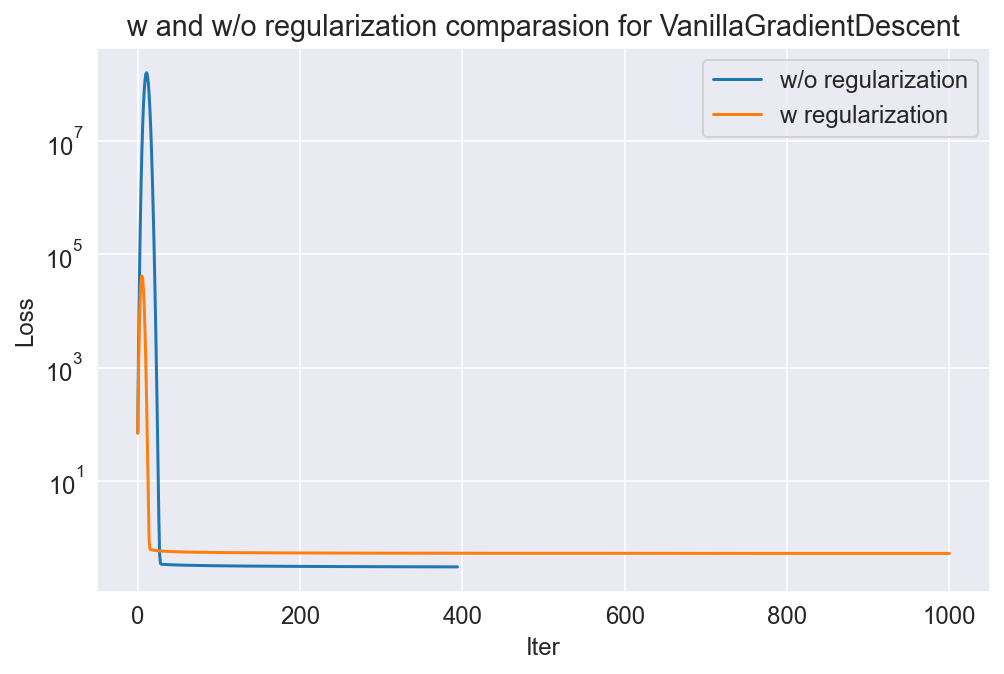

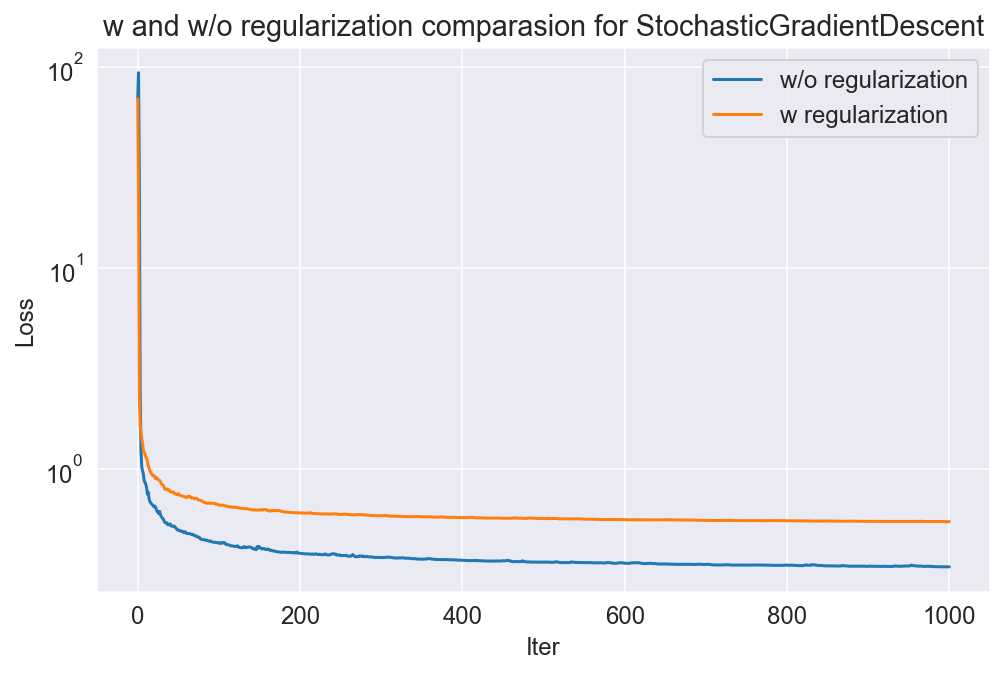

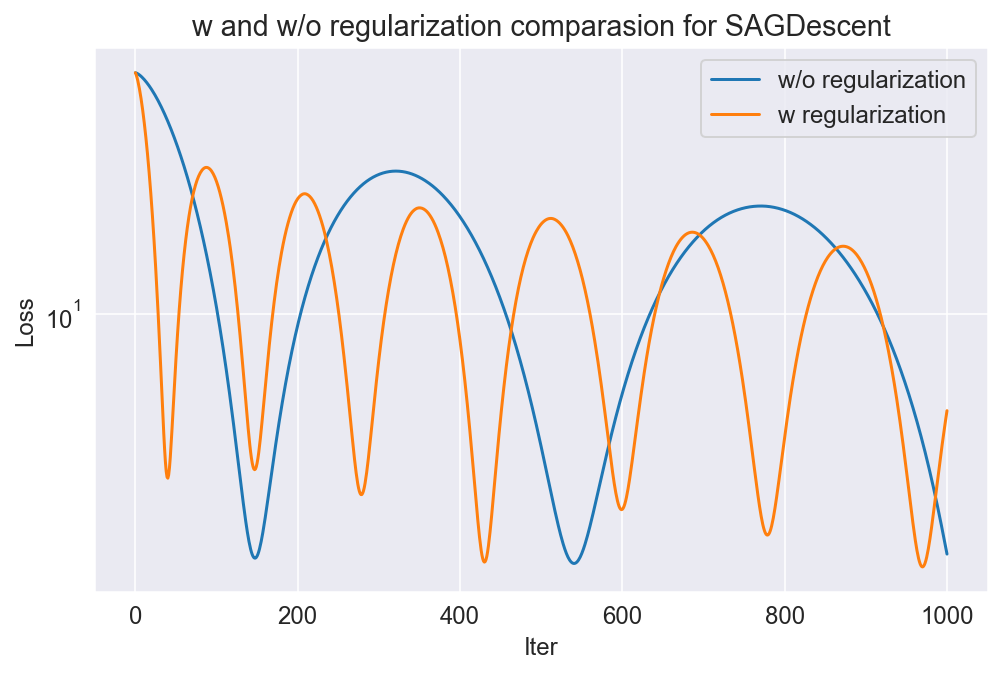

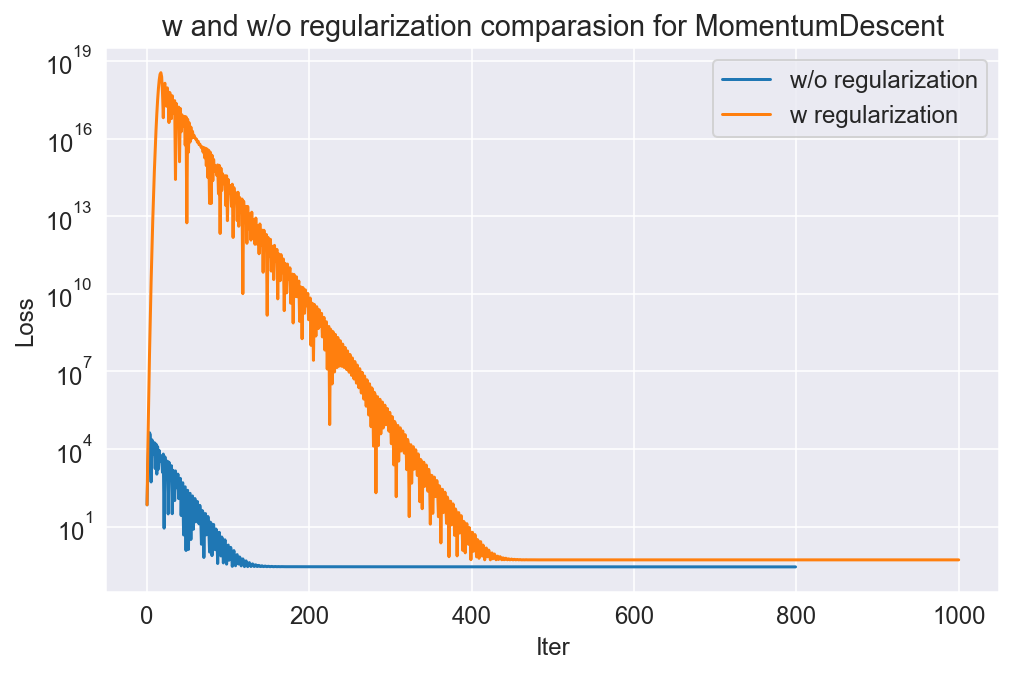

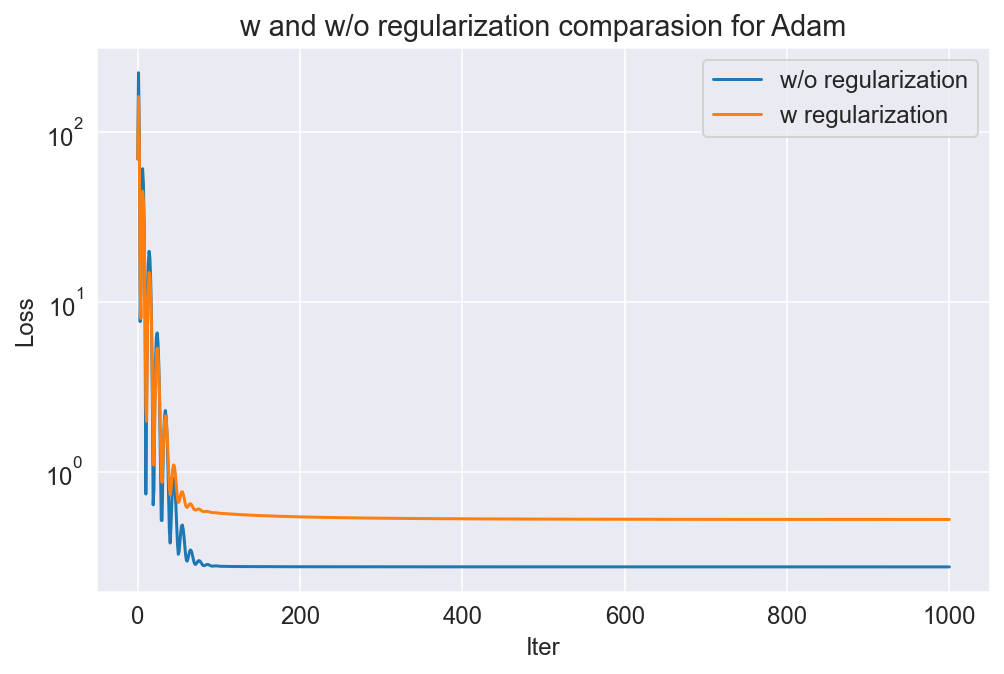

In [108]:
for descent_model in descent_models:
    plt.figure()
    plt.title(f"w and w/o regularization comparasion for {descent_model.__name__}")
    plt.plot(info_dict[descent_model.__name__]["loss_history"], label="w/o regularization")
    plt.plot(info_dict_reg[descent_model.__name__]["loss_history"], label="w regularization")
    plt.yscale("log")
    plt.xlabel("Iter")
    plt.ylabel("Loss")
    plt.legend()

Если уменьшить коэффициент, то результаты оказываются ближе к результатам без регуляризации, но всё ещё хуже. На Vanilla лосс теперь меньше улетает вверх на первых итерациях, но вот на momentum наоборот.

## Задание 8. Альтернативные функции потерь (1 балл)

В этом задании вам предстоит использовать другую функцию потерь для нашей задачи регрессии. В качестве функции потерь мы выбрали **LogCosh** и **HuberLoss**:

$$
    L(y, a)
    =
    \log\left(\cosh(a - y)\right).
$$

$$
L_{\text{Huber}}(y, a) = \frac{1}{n} \sum_{i=1}^{n}
\begin{cases}
   \frac{1}{2} (a_i - y_i)^2, & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot |a_i - y_i| - \frac{1}{2} \delta^2, & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$

Самостоятельно продифференцируйте данные функции потерь чтобы найти их градиенты _(требуется показать не только результат, но и промежуточные вычисления)_:

**Решение:**

Программно реализуйте функции потерь и их градиенты для LogCosh и HuberLoss в файле `linear_regression.py`. После этого обучите все пять методов градиентного спуска (без регуляризации) с этими лоссами аналогично заданию 5 и сравните качество с результатами из задания 5, где использовался MSE.

Имплементировать эти функции потерь необходимо при помощи наследования от `linear_regression.LossFunction` и имплементирования всех абстрактных методов. Аналитическое решение для этих функций выводить и имплементировать не требуется.



### Кулинарно-социализационный бонус. (0.5 балла)

Отличный способ провести осенние вечера - поделиться теплом с друзьями и близкими. Выберите рецепт, который соответствует вашему настроению, приготовьте выбранное блюдо и угостите хотя бы одного человека им. Кратко опишите ваши впечатления, прикрепите рецепт и фотографии блюда и довольного гостя.